# Random-exit continuation stability test

This notebook implements the pilot and analysis in `random_exit_continuation_stability_test.md`.
It tests whether correctness probabilities are compatible with a nondecreasing process **within each realized model/question trajectory**. It never aligns absolute or normalized token positions across questions.

Workflow:

1. recursively discover every selected benchmark/model run;
2. read top-level `correct` directly from each raw random-exit JSONL and skip runs that are not fully evaluated in place;
3. retain positions with all configured stochastic continuations and trajectories with at least the configured minimum number of valid positions;
4. fit weighted binomial PAVA and compute per-trajectory likelihood discrepancy $d_i$ and reversal magnitude $A_i$;
5. run the monotone parametric bootstrap and the separate question bootstrap;
6. expose the exact data behind every chart as a displayed/exported table;
7. run implementation/protocol checks and Holm-corrected benchmark/model tests;
8. export headline, completeness, regression, chart-data, model, and benchmark/model tables.

All paths are repository-relative. Analysis functions are defined in this notebook rather than imported from project Python files.

In [1]:
from pathlib import Path
import html
import json
from typing import Any, Iterable, Sequence

try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None

import numpy as np
import pandas as pd
from IPython.display import HTML, display

OUTPUT_DIR = Path("output/random_exit")
PREPARED_DIR = Path("data/random_exit")
TABLE_DIR = Path("output/random_exit/analysis/stability")
FIX_LOG_DIR = Path("examples/fix")

# None discovers all future runs recursively. Use sets to select a pilot subset.
BENCHMARKS = None       # Example: {"math500", "aime26"}
MODELS = None           # Example: {"qwen35_4b", "qwen35_9b"}
DOMAIN_BY_BENCHMARK = {
    "math500": "Mathematics",
    "aime26": "Mathematics",
    "gsm8k": "Mathematics",
    "gsm8k": "Mathematics",
    "humaneval": "Code",
    "livecodebench": "Code",
    "truthfulqa": "Factuality",
    "halueval": "Factuality",
    "mmlu_pro_subset": "Scientific"
}

MONOTONE_BOOTSTRAP_REPLICATES = 1_000
RUN_QUESTION_BOOTSTRAP = False  # Set True to estimate confidence intervals across questions.
QUESTION_BOOTSTRAP_REPLICATES = 1_000
BOOTSTRAP_SEED = 0
EXPECTED_DESIGN = {
    "sample_size": 128,
    "spacing": 16,
    "max_positions": 64,
    "num_runs": 8,
    "min_valid_positions": 5,
}


## Self-contained analysis implementation

The cell below contains JSONL discovery/loading, weighted PAVA, likelihood and reversal statistics, macro-averaging, and both bootstrap procedures. Keeping these definitions here makes the notebook auditable without tracing imports into project modules.

In [2]:
def read_jsonl(path: str | Path) -> list[dict[str, Any]]:
    path = Path(path)
    rows: list[dict[str, Any]] = []
    with path.open("r", encoding="utf-8") as handle:
        for file_line, line in enumerate(handle, start=1):
            if not line.strip():
                continue
            try:
                row = json.loads(line)
            except json.JSONDecodeError as error:
                raise ValueError(f"Invalid JSON in {path} at line {file_line}: {error}") from error
            if not isinstance(row, dict):
                raise ValueError(f"Expected a JSON object in {path} at line {file_line}")
            rows.append(row)
    return rows


def discover_runs(
    output_dir: str | Path = "output/random_exit",
    prepared_dir: str | Path = "data/random_exit",
    *,
    benchmarks: Iterable[str] | None = None,
    models: Iterable[str] | None = None,
) -> pd.DataFrame:
    """Recursively find raw runs and their prepared/metadata companions."""
    output_dir = Path(output_dir)
    prepared_dir = Path(prepared_dir)
    benchmark_filter = set(benchmarks) if benchmarks else None
    model_filter = set(models) if models else None
    found: list[dict[str, Any]] = []
    for raw in sorted(output_dir.rglob("*.jsonl")):
        # Temporarily ignore alternate gpt-oss runs that duplicate the high runs.
        if raw.name.endswith(".gpt_oss_20b_2.jsonl"):
            continue
        if raw.name.endswith(".evaluated.jsonl") or "analysis" in raw.parts:
            continue
        first_row: dict[str, Any] | None = None
        with raw.open("r", encoding="utf-8") as handle:
            for line in handle:
                if not line.strip():
                    continue
                try:
                    value = json.loads(line)
                except json.JSONDecodeError as error:
                    raise ValueError(f"Invalid first JSON row in {raw}: {error}") from error
                if isinstance(value, dict):
                    first_row = value
                break
        if first_row is None:
            continue
        data_id = first_row.get("data_id")
        model = first_row.get("model")
        benchmark = data_id.partition(":")[0] if isinstance(data_id, str) else ""
        if not benchmark or not isinstance(model, str) or not model:
            raise ValueError(f"Cannot identify benchmark/model from first row of {raw}")
        if benchmark_filter is not None and benchmark not in benchmark_filter:
            continue
        if model_filter is not None and model not in model_filter:
            continue
        found.append(
            {
                "benchmark": benchmark,
                "model": model,
                "raw": raw,
                "prepared": prepared_dir / benchmark / f"{benchmark}.{model}.jsonl",
                "metadata": raw.with_suffix(".metadata.json"),
            }
        )
    if not found:
        raise ValueError(f"No random-exit runs found under {output_dir}")
    result = pd.DataFrame(found)
    duplicates = result.duplicated(["benchmark", "model"], keep=False)
    if duplicates.any():
        values = result.loc[duplicates, ["benchmark", "model", "raw"]]
        raise ValueError(f"Multiple raw files identify the same run:\n{values.to_string(index=False)}")
    return result


def validate_companions(runs: pd.DataFrame) -> None:
    columns = ["raw", "prepared", "metadata"]
    missing = [str(path) for column in columns for path in runs[column] if not Path(path).is_file()]
    if missing:
        raise FileNotFoundError("Missing random-exit companion files:\n" + "\n".join(missing))


def pava_binomial(successes: Sequence[int], trials: Sequence[int]) -> np.ndarray:
    """Binomial MLE under nondecreasing probabilities via weighted PAVA."""
    x = np.asarray(successes, dtype=float)
    n = np.asarray(trials, dtype=float)
    if x.ndim != 1 or n.shape != x.shape or len(x) == 0:
        raise ValueError("successes and trials must be nonempty one-dimensional arrays")
    if np.any(n <= 0) or np.any(x < 0) or np.any(x > n):
        raise ValueError("Binomial counts must satisfy 0 <= successes <= trials")
    blocks: list[list[float]] = []
    for index, (success, total) in enumerate(zip(x, n, strict=True)):
        blocks.append([float(index), float(index), success, total])
        while len(blocks) >= 2:
            left, right = blocks[-2], blocks[-1]
            if left[2] / left[3] <= right[2] / right[3]:
                break
            blocks[-2:] = [[left[0], right[1], left[2] + right[2], left[3] + right[3]]]
    fitted = np.empty(len(x), dtype=float)
    for start, end, success, total in blocks:
        fitted[int(start) : int(end) + 1] = success / total
    return fitted


def binomial_log_likelihood(successes: Sequence[int], trials: Sequence[int], probabilities: Sequence[float]) -> float:
    x = np.asarray(successes, dtype=float)
    n = np.asarray(trials, dtype=float)
    p = np.asarray(probabilities, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        success_term = np.where(x == 0, 0.0, x * np.log(p))
        failure_term = np.where(n == x, 0.0, (n - x) * np.log1p(-p))
    return float(np.sum(success_term + failure_term))


def trajectory_statistics(successes: Sequence[int], trials: Sequence[int]) -> dict[str, Any]:
    x = np.asarray(successes, dtype=int)
    n = np.asarray(trials, dtype=int)
    observed = x / n
    fitted = pava_binomial(x, n)
    discrepancy = 2.0 * (
        binomial_log_likelihood(x, n, observed)
        - binomial_log_likelihood(x, n, fitted)
    ) / len(x)
    pair_drops = [max(float(observed[a] - observed[b]), 0.0)
                  for a in range(len(x)) for b in range(a + 1, len(x))]
    return {
        "d": max(float(discrepancy), 0.0),
        "a": float(np.mean(pair_drops)) if pair_drops else 0.0,
        "observed_probabilities": observed,
        "isotonic_probabilities": fitted,
    }


def load_run(
    run: pd.Series,
) -> tuple[pd.DataFrame, dict[str, Any], pd.DataFrame, pd.DataFrame]:
    metadata = json.loads(Path(run.metadata).read_text(encoding="utf-8"))
    settings = metadata.get("resolved", {}).get("random_exit", {})
    num_runs = int(settings.get("num_runs", 0))
    min_positions = int(settings.get("min_valid_positions", 0))
    if num_runs < 1 or min_positions < 1:
        raise ValueError(f"Invalid random-exit settings in {run.metadata}")

    prepared_records = read_jsonl(run.prepared)
    manifest_ids = [record.get("data_id") for record in prepared_records]
    if any(not isinstance(value, str) for value in manifest_ids) or len(set(manifest_ids)) != len(manifest_ids):
        raise ValueError(f"Prepared input has invalid or duplicate data_id values: {run.prepared}")

    records = read_jsonl(run.raw)
    rows = pd.DataFrame(records)
    required = {"key", "data_id", "line_number", "model", "position", "num_run", "ok", "correct"}
    missing = sorted(required - set(rows.columns))
    if missing:
        raise ValueError(f"{run.raw} is missing columns: {', '.join(missing)}")
    if rows["key"].duplicated().any():
        raise ValueError(f"Duplicate continuation keys in {run.raw}")
    if not rows["correct"].map(lambda value: isinstance(value, (bool, np.bool_))).all():
        raise ValueError(f"Every row in {run.raw} must have boolean correct")
    unknown = sorted(set(rows["data_id"]) - set(manifest_ids))
    if unknown:
        raise ValueError(f"Evaluated rows are absent from prepared manifest: {unknown[:10]}")
    rows["benchmark"] = str(run.benchmark)
    rows["model"] = str(run.model)
    rows["trajectory_id"] = rows["benchmark"] + "::" + rows["model"] + "::" + rows["data_id"]

    position_rows: list[dict[str, Any]] = []
    expected_runs = set(range(num_runs))
    for (trajectory_id, data_id, position), group in rows.groupby(
        ["trajectory_id", "data_id", "position"], sort=False
    ):
        run_numbers = set(int(value) for value in group["num_run"])
        complete = len(group) == num_runs and run_numbers == expected_runs and bool(group["ok"].eq(True).all())
        position_rows.append(
            {
                "benchmark": str(run.benchmark),
                "model": str(run.model),
                "trajectory_id": trajectory_id,
                "data_id": data_id,
                "position": int(position),
                "observed_runs": len(group),
                "successful_runs": int(group["ok"].eq(True).sum()),
                "expected_runs": num_runs,
                "complete": complete,
                "successes": int(group["correct"].sum()) if complete else np.nan,
            }
        )
    positions = pd.DataFrame(position_rows)
    complete_counts = positions.loc[positions["complete"]].groupby("trajectory_id").size()
    eligible = set(complete_counts[complete_counts >= min_positions].index)

    trajectory_rows: list[dict[str, Any]] = []
    for trajectory_id, group in positions.loc[
        positions["complete"] & positions["trajectory_id"].isin(eligible)
    ].groupby("trajectory_id", sort=False):
        group = group.sort_values("position")
        stats = trajectory_statistics(
            group["successes"].astype(int).to_numpy(),
            group["expected_runs"].astype(int).to_numpy(),
        )
        trajectory_rows.append(
            {
                "benchmark": str(run.benchmark),
                "model": str(run.model),
                "trajectory_id": trajectory_id,
                "data_id": group["data_id"].iloc[0],
                "num_positions": len(group),
                "d": stats["d"],
                "a": stats["a"],
                "successes": group["successes"].astype(int).to_list(),
                "trials": group["expected_runs"].astype(int).to_list(),
                "isotonic_probabilities": stats["isotonic_probabilities"].tolist(),
            }
        )
    trajectories = pd.DataFrame(trajectory_rows)
    manifest_count = len(manifest_ids)
    eligible_count = len(trajectories)
    completeness = pd.DataFrame([{
        "benchmark": str(run.benchmark),
        "model": str(run.model),
        "manifest_trajectories": manifest_count,
        "observed_trajectories": int(positions["trajectory_id"].nunique()),
        "eligible_trajectories": eligible_count,
        "excluded_trajectories": manifest_count - eligible_count,
        "excluded_fraction": (manifest_count - eligible_count) / manifest_count if manifest_count else np.nan,
        "complete_positions": int(positions["complete"].sum()),
        "observed_rows": len(rows),
        "num_runs": num_runs,
        "min_valid_positions": min_positions,
    }])
    return trajectories, metadata, completeness, positions


def macro_average(values: pd.DataFrame, column: str) -> tuple[float, pd.DataFrame, pd.DataFrame]:
    cells = values.groupby(["benchmark", "model"], as_index=False)[column].mean()
    models = cells.groupby("model", as_index=False)[column].mean()
    return float(models[column].mean()), cells, models


def parametric_monotone_bootstrap(
    trajectories: pd.DataFrame,
    *,
    replicates: int = 10_000,
    seed: int = 0,
    trajectory_sample_replicates: int = 100,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    if trajectories.empty:
        raise ValueError("No eligible trajectories for bootstrap")
    rng = np.random.default_rng(seed)
    records: list[dict[str, Any]] = []
    trajectory_sample: list[dict[str, Any]] = []
    cell_records: list[dict[str, Any]] = []
    null_a_sums = np.zeros(len(trajectories), dtype=float)
    null_d_sums = np.zeros(len(trajectories), dtype=float)
    for replicate in range(replicates):
        simulated: list[dict[str, Any]] = []
        for row_index, row in enumerate(trajectories.itertuples(index=False)):
            trials = np.asarray(row.trials, dtype=int)
            successes = rng.binomial(trials, np.asarray(row.isotonic_probabilities))
            stats = trajectory_statistics(successes, trials)
            null_a_sums[row_index] += stats["a"]
            null_d_sums[row_index] += stats["d"]
            if replicate < trajectory_sample_replicates:
                trajectory_sample.append(
                    {
                        "replicate": replicate,
                        "trajectory_id": row.trajectory_id,
                        "d": stats["d"],
                        "a": stats["a"],
                    }
                )
            simulated.append({"benchmark": row.benchmark, "model": row.model,
                              "d": stats["d"], "a": stats["a"]})
        simulated_frame = pd.DataFrame(simulated)
        d_value, cells_d, _models = macro_average(simulated_frame, "d")
        a_value, cells_a, _models = macro_average(simulated_frame, "a")
        cells = cells_d.merge(cells_a, on=["benchmark", "model"])
        cells.insert(0, "replicate", replicate)
        cell_records.extend(cells.to_dict(orient="records"))
        records.append({"replicate": replicate, "d": d_value, "a": a_value})
    null_means = trajectories[["trajectory_id"]].copy()
    null_means["a_null_mean"] = null_a_sums / replicates
    null_means["d_null_mean"] = null_d_sums / replicates
    return (pd.DataFrame(records), null_means, pd.DataFrame(trajectory_sample),
            pd.DataFrame(cell_records))


def question_bootstrap(
    trajectories: pd.DataFrame,
    *,
    replicates: int = 10_000,
    seed: int = 1,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    required = {"benchmark", "model", "data_id", "d", "a", "a_null_mean"}
    if missing := sorted(required - set(trajectories.columns)):
        raise ValueError(f"Question bootstrap is missing columns: {missing}")
    rng = np.random.default_rng(seed)
    benchmark_ids = {
        benchmark: np.asarray(sorted(group["data_id"].unique()), dtype=object)
        for benchmark, group in trajectories.groupby("benchmark")
    }
    records: list[dict[str, Any]] = []
    cell_records: list[dict[str, Any]] = []
    model_records: list[dict[str, Any]] = []
    for replicate in range(replicates):
        pieces: list[pd.DataFrame] = []
        for benchmark, identifiers in benchmark_ids.items():
            draws = rng.choice(identifiers, size=len(identifiers), replace=True)
            source = trajectories.loc[trajectories["benchmark"] == benchmark]
            for draw_index, data_id in enumerate(draws):
                selected = source.loc[source["data_id"] == data_id].copy()
                selected["bootstrap_question"] = draw_index
                pieces.append(selected)
        sampled = pd.concat(pieces, ignore_index=True)
        d_value, cells_d, models_d = macro_average(sampled, "d")
        a_value, cells_a, models_a = macro_average(sampled, "a")
        excess_value, cells_excess, models_excess = macro_average(
            sampled.assign(a_excess=sampled["a"] - sampled["a_null_mean"]), "a_excess"
        )
        records.append({"replicate": replicate, "d": d_value, "a": a_value,
                        "a_excess": excess_value})
        cells = cells_d.merge(cells_a, on=["benchmark", "model"]).merge(
            cells_excess, on=["benchmark", "model"]
        )
        cells.insert(0, "replicate", replicate)
        cell_records.extend(cells.to_dict(orient="records"))
        models = models_d.merge(models_a, on="model").merge(models_excess, on="model")
        models.insert(0, "replicate", replicate)
        model_records.extend(models.to_dict(orient="records"))
    return pd.DataFrame(records), pd.DataFrame(cell_records), pd.DataFrame(model_records)


def holm_adjust(p_values: Sequence[float]) -> np.ndarray:
    values = np.asarray(p_values, dtype=float)
    order = np.argsort(values)
    adjusted = np.empty(len(values), dtype=float)
    running = 0.0
    for rank, index in enumerate(order):
        running = max(running, (len(values) - rank) * values[index])
        adjusted[index] = min(running, 1.0)
    return adjusted


def summarize(
    trajectories: pd.DataFrame,
    null_bootstrap: pd.DataFrame,
    question_samples: pd.DataFrame | None,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    observed_d, cells_d, models_d = macro_average(trajectories, "d")
    observed_a, cells_a, models_a = macro_average(trajectories, "a")
    null_a = float(null_bootstrap["a"].mean())
    p_d = (1 + int((null_bootstrap["d"] >= observed_d).sum())) / (len(null_bootstrap) + 1)
    p_a = (1 + int((null_bootstrap["a"] >= observed_a).sum())) / (len(null_bootstrap) + 1)
    headline = pd.DataFrame([{
        "d_overall": observed_d,
        "d_ci_low": question_samples["d"].quantile(0.025) if question_samples is not None else np.nan,
        "d_ci_high": question_samples["d"].quantile(0.975) if question_samples is not None else np.nan,
        "p_d": p_d,
        "a_observed": observed_a,
        "a_null_expected": null_a,
        "a_excess": observed_a - null_a,
        "a_excess_ci_low": question_samples["a_excess"].quantile(0.025) if question_samples is not None else np.nan,
        "a_excess_ci_high": question_samples["a_excess"].quantile(0.975) if question_samples is not None else np.nan,
        "p_a": p_a,
        "eligible_trajectories": len(trajectories),
    }])
    cells = cells_d.merge(cells_a, on=["benchmark", "model"])
    models = models_d.merge(models_a, on="model")
    return headline, cells, models


## Discover evaluated runs

Discovery uses `Path(...).rglob("*.jsonl")`. Benchmark and model identity are read from each raw file, while prepared input and metadata sidecars are selected by benchmark/model identity and filename stem. Correctness is read directly from the raw JSONL. Runs without a boolean `correct` value on every row are reported and skipped; this notebook never runs evaluation.

In [3]:
runs = discover_runs(
    OUTPUT_DIR,
    PREPARED_DIR,
    benchmarks=BENCHMARKS,
    models=MODELS,
)
validate_companions(runs)

def evaluation_counts(path: str | Path) -> tuple[int, int]:
    records = read_jsonl(path)
    evaluated = sum(isinstance(record.get("correct"), bool) for record in records)
    return len(records), evaluated

evaluation_status = runs[["benchmark", "model", "raw"]].copy()
counts = evaluation_status["raw"].map(evaluation_counts)
evaluation_status["rows"] = counts.map(lambda value: value[0])
evaluation_status["evaluated_rows"] = counts.map(lambda value: value[1])
evaluation_status["fully_evaluated"] = evaluation_status["rows"].eq(
    evaluation_status["evaluated_rows"]
)
display(evaluation_status)

incomplete = evaluation_status.loc[~evaluation_status["fully_evaluated"]]
if not incomplete.empty:
    for row in incomplete.itertuples(index=False):
        print(
            f"Skipping unevaluated run {row.benchmark}/{row.model}: "
            f"{row.evaluated_rows:,}/{row.rows:,} rows have boolean correct"
        )
    complete_keys = evaluation_status.loc[
        evaluation_status["fully_evaluated"], ["benchmark", "model"]
    ]
    runs = runs.merge(complete_keys, on=["benchmark", "model"], how="inner")

if runs.empty:
    raise ValueError(
        "No fully evaluated raw random-exit runs are available. Run the standalone "
        "evaluator with --in-place before analysis."
    )

display(runs)


ValueError: Multiple raw files identify the same run:
      benchmark            model                                                       raw
        math500 gpt_oss_20b_high            output/random_exit/math500.gpt_oss_20b_2.jsonl
        math500 gpt_oss_20b_high         output/random_exit/math500.gpt_oss_20b_high.jsonl
mmlu_pro_subset gpt_oss_20b_high    output/random_exit/mmlu_pro_subset.gpt_oss_20b_2.jsonl
mmlu_pro_subset gpt_oss_20b_high output/random_exit/mmlu_pro_subset.gpt_oss_20b_high.jsonl
     truthfulqa gpt_oss_20b_high         output/random_exit/truthfulqa.gpt_oss_20b_2.jsonl
     truthfulqa gpt_oss_20b_high      output/random_exit/truthfulqa.gpt_oss_20b_high.jsonl

## Load complete positions and audit the design

A position is usable only when all configured continuation slots are present, uniquely numbered, and successful. Successfully generated malformed or incorrect answers remain valid with `correct=False`. A trajectory enters the monotonicity analysis only when it has at least `min_valid_positions` complete positions.

The audit explicitly compares each sidecar against the preregistered design. A pilot with different settings can validate implementation, but should not be reported as the confirmatory experiment.

In [ ]:
trajectory_parts = []
position_parts = []
completeness_parts = []
metadata_rows = []

for run in runs.itertuples(index=False):
    trajectories_for_run, metadata, run_completeness, run_positions = load_run(pd.Series(run._asdict()))
    trajectory_parts.append(trajectories_for_run)
    completeness_parts.append(run_completeness)
    position_parts.append(run_positions)
    settings = metadata["resolved"]["random_exit"]
    metadata_rows.append({
        "benchmark": run.benchmark,
        "model": run.model,
        **{field: settings.get(field) for field in EXPECTED_DESIGN},
    })

trajectories = pd.concat(trajectory_parts, ignore_index=True)
positions = pd.concat(position_parts, ignore_index=True)
completeness = pd.concat(completeness_parts, ignore_index=True)
design_audit = pd.DataFrame(metadata_rows)
for field, expected in EXPECTED_DESIGN.items():
    design_audit[f"{field}_matches_plan"] = design_audit[field].eq(expected)

if trajectories.empty:
    raise ValueError("No trajectories currently meet min_valid_positions")

display(design_audit)
display(completeness)
if not design_audit.filter(like="_matches_plan").all(axis=None):
    print("PILOT ONLY: at least one resolved setting differs from the confirmatory plan.")


,benchmark,model,sample_size,spacing,max_positions,num_runs,min_valid_positions,sample_size_matches_plan,spacing_matches_plan,max_positions_matches_plan,num_runs_matches_plan,min_valid_positions_matches_plan
0,aime26,gpt_oss_20b_high,64,32,64,8,5,False,False,True,True,True
1,livecodebench,gpt_oss_20b_high,64,32,64,8,5,False,False,True,True,True
2,math500,gpt_oss_20b_high,64,32,64,8,5,False,False,True,True,True
3,math500,qwen35_4b,64,32,64,8,5,False,False,True,True,True
4,mmlu_pro_subset,gpt_oss_20b_high,64,32,64,8,5,False,False,True,True,True
5,mmlu_pro_subset,qwen35_4b,64,32,64,8,5,False,False,True,True,True
6,truthfulqa,gpt_oss_20b_high,64,32,64,8,5,False,False,True,True,True
7,truthfulqa,qwen35_4b,64,32,64,8,5,False,False,True,True,True


,benchmark,model,manifest_trajectories,observed_trajectories,eligible_trajectories,excluded_trajectories,excluded_fraction,complete_positions,observed_rows,num_runs,min_valid_positions
0,aime26,gpt_oss_20b_high,29,29,29,0,0.000000,1856,14848,8,5
1,livecodebench,gpt_oss_20b_high,64,64,64,0,0.000000,3618,28944,8,5
2,math500,gpt_oss_20b_high,128,122,122,6,0.046875,4278,34224,8,5
3,math500,qwen35_4b,128,128,128,0,0.000000,7654,61232,8,5
4,mmlu_pro_subset,gpt_oss_20b_high,196,186,186,10,0.051020,6654,53232,8,5
5,mmlu_pro_subset,qwen35_4b,196,196,196,0,0.000000,11786,94288,8,5
6,truthfulqa,gpt_oss_20b_high,128,126,126,2,0.015625,4749,37992,8,5
7,truthfulqa,qwen35_4b,128,128,128,0,0.000000,8192,65536,8,5


PILOT ONLY: at least one resolved setting differs from the confirmatory plan.


## Executable implementation and protocol checks

These checks turn the pilot checklist in the companion markdown into executable tests. Synthetic cases verify weighted isotonic regression (PAVA), likelihood discrepancy, reversal magnitude, macro-averaging, and Holm correction. Run-level checks verify the realized exit grid, position cap, continuation completeness, minimum-$K_i$ rule, and stored prompt provenance. A failed check stops the notebook before inferential results are reported.

In [ ]:
implementation_checks = []

def add_check(name: str, passed: bool, detail: str) -> None:
    implementation_checks.append({"check": name, "passed": bool(passed), "detail": detail})

weighted_fit = pava_binomial([1, 0, 4], [1, 3, 4])
add_check("weighted PAVA pools by trial count", np.allclose(weighted_fit, [0.25, 0.25, 1.0]), str(weighted_fit))
monotone_stats = trajectory_statistics([0, 2, 4], [4, 4, 4])
add_check("monotone sequence has zero discrepancy", np.isclose(monotone_stats["d"], 0.0), f'd={monotone_stats["d"]}')
reversal_stats = trajectory_statistics([4, 0], [4, 4])
add_check("complete reversal has unit magnitude", np.isclose(reversal_stats["a"], 1.0), f'a={reversal_stats["a"]}')
macro_fixture = pd.DataFrame({"benchmark": ["b1", "b1", "b2"], "model": ["m1"] * 3, "d": [1.0, 3.0, 10.0]})
macro_value, _, _ = macro_average(macro_fixture, "d")
add_check("macro-average gives benchmarks equal weight", np.isclose(macro_value, 6.0), f'd={macro_value}')
holm_fixture = holm_adjust([0.01, 0.03, 0.04])
add_check("Holm adjustment is step-down monotone", np.allclose(holm_fixture, [0.03, 0.06, 0.06]), str(holm_fixture))
implementation_checks = pd.DataFrame(implementation_checks)
display(implementation_checks)
if not implementation_checks["passed"].all():
    raise AssertionError("One or more implementation checks failed")

protocol_rows = []
for design in design_audit.itertuples(index=False):
    run_positions = positions.loc[(positions["benchmark"] == design.benchmark) & (positions["model"] == design.model)]
    complete = run_positions.loc[run_positions["complete"]]
    grouped = complete.groupby("trajectory_id")["position"]
    same_offset = grouped.apply(lambda values: (values.astype(int) % int(design.spacing)).nunique() == 1).all()
    separated = grouped.apply(lambda values: np.diff(np.sort(values.astype(int))).min() >= int(design.spacing) if len(values) > 1 else True).all()
    prompt_rows = read_jsonl(runs.loc[(runs["benchmark"] == design.benchmark) & (runs["model"] == design.model), "prepared"].iloc[0])
    prompt_ok = all(isinstance(row.get("response", {}).get("input"), str) and isinstance(row.get("response", {}).get("content"), str) for row in prompt_rows)
    protocol_rows.append({
        "benchmark": design.benchmark, "model": design.model,
        "random_offset_grid": bool(same_offset), "minimum_spacing": bool(separated),
        "position_cap": bool(grouped.size().le(int(design.max_positions)).all()),
        "complete_positions_have_R_runs": bool((complete["observed_runs"] == int(design.num_runs)).all() and (complete["successful_runs"] == int(design.num_runs)).all()),
        "eligible_trajectories_meet_min_K": bool(trajectories.loc[(trajectories["benchmark"] == design.benchmark) & (trajectories["model"] == design.model), "num_positions"].ge(int(design.min_valid_positions)).all()),
        "stored_prompt_available": bool(prompt_ok),
    })
protocol_checks = pd.DataFrame(protocol_rows)
display(protocol_checks)
if not protocol_checks.drop(columns=["benchmark", "model"]).all(axis=None):
    raise AssertionError("One or more realized-data protocol checks failed")


,check,passed,detail
0,weighted PAVA pools by trial count,True,[0.25 0.25 1. ]
1,monotone sequence has zero discrepancy,True,d=0.0
2,complete reversal has unit magnitude,True,a=1.0
3,macro-average gives benchmarks equal weight,True,d=6.0
4,Holm adjustment is step-down monotone,True,[0.03 0.06 0.06]


,benchmark,model,random_offset_grid,minimum_spacing,position_cap,complete_positions_have_R_runs,eligible_trajectories_meet_min_K,stored_prompt_available
0,aime26,gpt_oss_20b_high,True,True,True,True,True,True
1,livecodebench,gpt_oss_20b_high,True,True,True,True,True,True
2,math500,gpt_oss_20b_high,True,True,True,True,True,True
3,math500,qwen35_4b,True,True,True,True,True,True
4,mmlu_pro_subset,gpt_oss_20b_high,True,True,True,True,True,True
5,mmlu_pro_subset,qwen35_4b,True,True,True,True,True,True
6,truthfulqa,gpt_oss_20b_high,True,True,True,True,True,True
7,truthfulqa,qwen35_4b,True,True,True,True,True,True


## Within-trajectory estimates

Rows are sorted by their original position only inside a model/question trajectory. The notebook does not pool or align token positions. `d` is the normalized log-likelihood loss under monotonicity; `a` is the average positive earlier-to-later drop. The table below contains every point in the chart, including the weighted isotonic-regression fit.

## Answer consistency and early convergence

At each complete eight-sample exit, compare extracted answers **in pairs** with the benchmark evaluator in both directions. For Math500, disable percentage equivalence for answer-to-answer comparisons. A nontransitive comparison has no well-defined unique-answer count and is flagged for review. Failed-answer convergence (one wrong semantic answer) and failed-answer diversity (multiple wrong semantic answers) are separate hypotheses. Agreement does not imply correctness. The grey chart line is unique semantic answers divided by eight; invalid or nontransitive groups have a gap.

This analysis is enabled only for TruthfulQA and Math500. LiveCodeBench and other benchmarks retain their accuracy/entropy plots but receive no unique-answer count or grey consistency line until a validated pairwise behavior comparator is supplied.


In [ ]:
# from random_exit.answer_consistency import SUPPORTED_PAIRWISE_BENCHMARKS, answer_consistency, all_high_score_test

# complete_keys = positions.loc[positions["complete"], ["benchmark", "model", "data_id", "position"]].drop_duplicates()
# eligible_ids = set(trajectories["trajectory_id"])
# consistency_rows, complete_exit_rows = [], []
# for run in runs.itertuples(index=False):
#     if run.benchmark not in SUPPORTED_PAIRWISE_BENCHMARKS:
#         print(f"Skipping semantic answer comparison for {run.benchmark}; no validated pairwise comparator")
#         continue
#     evaluated = pd.DataFrame(read_jsonl(run.raw))
#     evaluated["benchmark"] = run.benchmark
#     evaluated["model"] = run.model
#     selected = evaluated.merge(complete_keys, on=["benchmark", "model", "data_id", "position"], how="inner")
#     selected = selected.loc[(selected["benchmark"].astype(str) + "::" + selected["model"].astype(str) + "::" + selected["data_id"].astype(str)).isin(eligible_ids)]
#     complete_exit_rows.extend(selected.to_dict("records"))
#     for (data_id, position), group in selected.groupby(["data_id", "position"], sort=False):
#         stats = answer_consistency(group.to_dict("records"), str(run.benchmark))
#         consistency_rows.append({"benchmark": run.benchmark, "model": run.model, "data_id": data_id,
#                                  "trajectory_id": f"{run.benchmark}::{run.model}::{data_id}",
#                                  "position": int(position), **stats})
# answer_consistency_curve_data = pd.DataFrame(consistency_rows) if consistency_rows else pd.DataFrame(columns=["benchmark", "model", "data_id", "trajectory_id", "position", "unique_answer_count", "sample_count", "all_answers_consistent", "wrong_answers_converged", "wrong_answers_diverse", "nontransitive_comparator"])
# answer_consistency_curve_data["unique_fraction"] = answer_consistency_curve_data["unique_answer_count"] / answer_consistency_curve_data["sample_count"]
# TABLE_DIR.mkdir(parents=True, exist_ok=True)
# answer_consistency_curve_data.to_csv(TABLE_DIR / "answer_consistency_positions.csv", index=False)
# display(answer_consistency_curve_data.head(20))
# display(answer_consistency_curve_data.groupby(["benchmark", "model"], as_index=False).agg(
#     positions=("position", "size"), all_consistent=("all_answers_consistent", "sum"),
#     wrong_converged=("wrong_answers_converged", "sum"), wrong_diverse=("wrong_answers_diverse", "sum"),
#     nontransitive=("nontransitive_comparator", "sum")))


,benchmark,model,data_id,num_positions,d,a
0,aime26,gpt_oss_20b_high,aime26:1,64,0.251884,0.002046
9,aime26,gpt_oss_20b_high,aime26:10,64,0.000000,0.000000
10,aime26,gpt_oss_20b_high,aime26:12,64,0.035711,0.000124
11,aime26,gpt_oss_20b_high,aime26:13,64,0.000000,0.000000
12,aime26,gpt_oss_20b_high,aime26:14,64,0.371050,0.009115
13,aime26,gpt_oss_20b_high,aime26:15,64,0.000000,0.000000
14,aime26,gpt_oss_20b_high,aime26:16,64,0.810904,0.014509
15,aime26,gpt_oss_20b_high,aime26:17,64,1.321316,0.029514
16,aime26,gpt_oss_20b_high,aime26:18,64,0.000000,0.000000
17,aime26,gpt_oss_20b_high,aime26:19,64,0.251116,0.004154


,benchmark,model,trajectory_id,data_id,exit_index,position,successes,expected_runs,p_hat,p_isotonic,residual
3437,livecodebench,gpt_oss_20b_high,livecodebench::gpt_oss_20b_high::livecodebench...,livecodebench:550,1,15,8,8,1.000,0.406250,0.593750
3438,livecodebench,gpt_oss_20b_high,livecodebench::gpt_oss_20b_high::livecodebench...,livecodebench:550,2,47,7,8,0.875,0.406250,0.468750
3439,livecodebench,gpt_oss_20b_high,livecodebench::gpt_oss_20b_high::livecodebench...,livecodebench:550,3,79,8,8,1.000,0.406250,0.593750
3440,livecodebench,gpt_oss_20b_high,livecodebench::gpt_oss_20b_high::livecodebench...,livecodebench:550,4,111,8,8,1.000,0.406250,0.593750
3441,livecodebench,gpt_oss_20b_high,livecodebench::gpt_oss_20b_high::livecodebench...,livecodebench:550,5,143,8,8,1.000,0.406250,0.593750
...,...,...,...,...,...,...,...,...,...,...,...
39820,truthfulqa,gpt_oss_20b_high,truthfulqa::gpt_oss_20b_high::truthfulqa:536,truthfulqa:536,22,689,0,8,0.000,0.211538,-0.211538
39821,truthfulqa,gpt_oss_20b_high,truthfulqa::gpt_oss_20b_high::truthfulqa:536,truthfulqa:536,23,721,0,8,0.000,0.211538,-0.211538
39822,truthfulqa,gpt_oss_20b_high,truthfulqa::gpt_oss_20b_high::truthfulqa:536,truthfulqa:536,24,753,0,8,0.000,0.211538,-0.211538
39823,truthfulqa,gpt_oss_20b_high,truthfulqa::gpt_oss_20b_high::truthfulqa:536,truthfulqa:536,25,785,0,8,0.000,0.211538,-0.211538


,benchmark,model,trajectory_id,data_id,line_number,full_log_path,full_log_file_line,status
0,aime26,gpt_oss_20b_high,aime26::gpt_oss_20b_high::aime26:1,aime26:1,1,examples/fix/aime26/full_3_replay_eval_gpt_oss...,2,matched
1,aime26,gpt_oss_20b_high,aime26::gpt_oss_20b_high::aime26:2,aime26:2,2,examples/fix/aime26/full_3_replay_eval_gpt_oss...,4,matched
2,aime26,gpt_oss_20b_high,aime26::gpt_oss_20b_high::aime26:3,aime26:3,3,examples/fix/aime26/full_3_replay_eval_gpt_oss...,1,matched
3,aime26,gpt_oss_20b_high,aime26::gpt_oss_20b_high::aime26:4,aime26:4,4,examples/fix/aime26/full_3_replay_eval_gpt_oss...,3,matched
4,aime26,gpt_oss_20b_high,aime26::gpt_oss_20b_high::aime26:5,aime26:5,5,examples/fix/aime26/full_3_replay_eval_gpt_oss...,6,matched
...,...,...,...,...,...,...,...,...
974,truthfulqa,qwen35_4b,truthfulqa::qwen35_4b::truthfulqa:777,truthfulqa:777,777,examples/fix/truthfulqa/full_1_replay_eval_qwe...,37,matched
975,truthfulqa,qwen35_4b,truthfulqa::qwen35_4b::truthfulqa:799,truthfulqa:799,799,examples/fix/truthfulqa/full_1_replay_eval_qwe...,17,matched
976,truthfulqa,qwen35_4b,truthfulqa::qwen35_4b::truthfulqa:801,truthfulqa:801,801,examples/fix/truthfulqa/full_1_replay_eval_qwe...,15,matched
977,truthfulqa,qwen35_4b,truthfulqa::qwen35_4b::truthfulqa:806,truthfulqa:806,806,examples/fix/truthfulqa/full_1_replay_eval_qwe...,12,matched


,benchmark,model,trajectory_id,data_id,line_number,method,exit_position,exit,correct
0,aime26,gpt_oss_20b_high,aime26::gpt_oss_20b_high::aime26:1,aime26:1,1,terminator_hf,560,True,True
1,aime26,gpt_oss_20b_high,aime26::gpt_oss_20b_high::aime26:1,aime26:1,1,dtsr,802,True,True
2,aime26,gpt_oss_20b_high,aime26::gpt_oss_20b_high::aime26:1,aime26:1,1,codestop,914,True,True
3,aime26,gpt_oss_20b_high,aime26::gpt_oss_20b_high::aime26:1,aime26:1,1,deer,914,True,True
4,aime26,gpt_oss_20b_high,aime26::gpt_oss_20b_high::aime26:1,aime26:1,1,entrocut,914,True,True
...,...,...,...,...,...,...,...,...,...
7063,truthfulqa,qwen35_4b,truthfulqa::qwen35_4b::truthfulqa:99,truthfulqa:99,99,dtsr,194,True,False
7064,truthfulqa,qwen35_4b,truthfulqa::qwen35_4b::truthfulqa:99,truthfulqa:99,99,codestop,420,True,False
7065,truthfulqa,qwen35_4b,truthfulqa::qwen35_4b::truthfulqa:99,truthfulqa:99,99,deer,642,True,False
7066,truthfulqa,qwen35_4b,truthfulqa::qwen35_4b::truthfulqa:99,truthfulqa:99,99,entrocut,642,True,False


/home/quanghung20gg/anaconda3/envs/verl/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/quanghung20gg/anaconda3/envs/verl/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


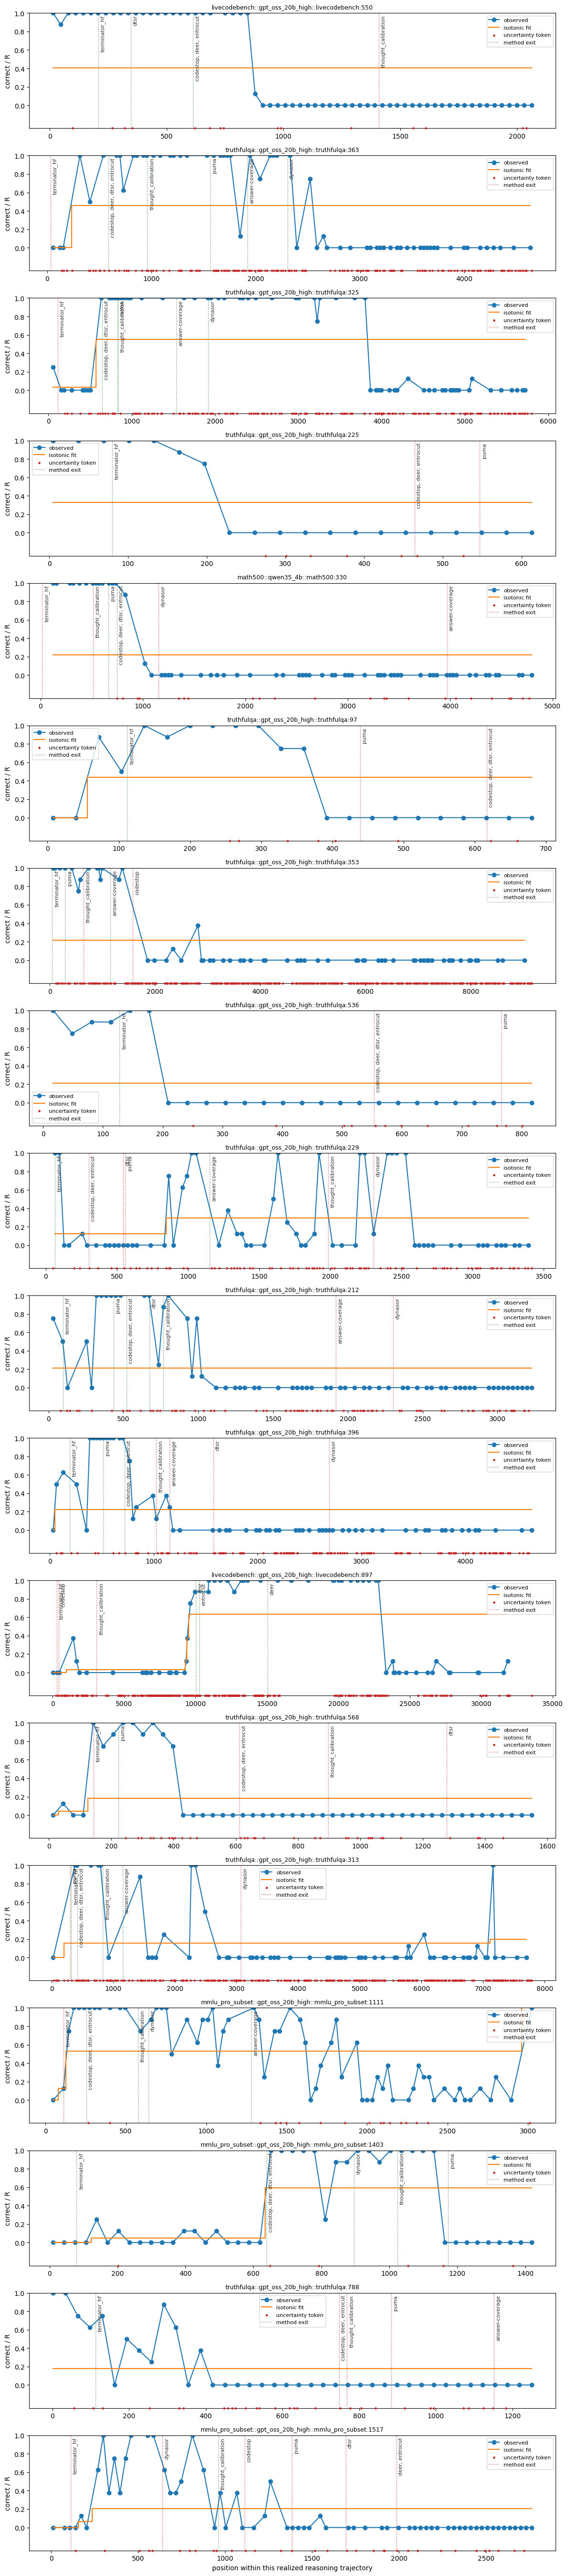

In [ ]:
trajectory_view = trajectories[[
    "benchmark", "model", "data_id", "num_positions", "d", "a"
]].sort_values(["benchmark", "model", "data_id"])
display(trajectory_view.head(20))

# Descriptive curves for a few trajectories; each x-axis belongs only to that trajectory.
complete_positions = positions.loc[positions["complete"]].copy()
complete_positions["p_hat"] = complete_positions["successes"] / complete_positions["expected_runs"]
selected_ids = trajectories.nlargest(min(18, len(trajectories)), "d")["trajectory_id"].tolist()
regression_parts = []
for trajectory_id in trajectories["trajectory_id"]:
    curve = complete_positions.loc[complete_positions["trajectory_id"] == trajectory_id].sort_values("position").copy()
    fitted = trajectories.loc[trajectories["trajectory_id"] == trajectory_id, "isotonic_probabilities"].iloc[0]
    curve["exit_index"] = np.arange(1, len(curve) + 1)
    curve["p_isotonic"] = np.asarray(fitted, dtype=float)
    curve["residual"] = curve["p_hat"] - curve["p_isotonic"]
    regression_parts.append(curve[["benchmark", "model", "trajectory_id", "data_id", "exit_index", "position", "successes", "expected_runs", "p_hat", "p_isotonic", "residual"]])
all_regression_curve_data = pd.concat(regression_parts, ignore_index=True)
regression_curve_data = all_regression_curve_data.loc[all_regression_curve_data["trajectory_id"].isin(selected_ids)].copy()
display(regression_curve_data)

# Match each selected random-exit trajectory to its original full-run JSONL record.
# When reruns overlap, the timestamp in the filename selects the newest record.
selected_trajectory_rows = all_regression_curve_data[["benchmark", "model", "trajectory_id", "data_id"]].drop_duplicates()
full_jsonl_records = {}
prepared_jsonl_records = {}
full_log_source_rows = []
full_log_exit_rows = []
for (benchmark, model), selected_group in selected_trajectory_rows.groupby(["benchmark", "model"], sort=False):
    matching_run = runs.loc[(runs["benchmark"] == benchmark) & (runs["model"] == model)]
    if len(matching_run) != 1:
        raise KeyError(f"Expected one random-exit run for {benchmark}/{model}, found {len(matching_run)}")
    prepared_by_id = {str(row["data_id"]): row for row in read_jsonl(matching_run.iloc[0]["prepared"])}
    wanted_lines = {int(prepared_by_id[str(data_id)]["line_number"]): str(data_id) for data_id in selected_group["data_id"]}
    candidates = {}
    for full_log_path in sorted((FIX_LOG_DIR / benchmark).glob("*.jsonl")):
        with full_log_path.open("r", encoding="utf-8") as handle:
            for file_line, line in enumerate(handle, start=1):
                if not line.strip():
                    continue
                record = json.loads(line)
                if record.get("model") != model or record.get("line_number") not in wanted_lines:
                    continue
                timestamp = "".join(full_log_path.stem.rsplit("_", 2)[-2:])
                key = int(record["line_number"])
                if key not in candidates or timestamp > candidates[key][0]:
                    candidates[key] = (timestamp, full_log_path, file_line, record)
    for trajectory in selected_group.itertuples(index=False):
        line_number = int(prepared_by_id[str(trajectory.data_id)]["line_number"])
        prepared_jsonl_records[trajectory.trajectory_id] = prepared_by_id[str(trajectory.data_id)]
        if line_number not in candidates:
            full_log_source_rows.append({
                "benchmark": benchmark, "model": model, "trajectory_id": trajectory.trajectory_id,
                "data_id": trajectory.data_id, "line_number": line_number, "full_log_path": None,
                "full_log_file_line": None, "status": "not found",
            })
            continue
        _timestamp, full_log_path, file_line, record = candidates[line_number]
        full_jsonl_records[trajectory.trajectory_id] = record
        full_log_source_rows.append({
            "benchmark": benchmark, "model": model, "trajectory_id": trajectory.trajectory_id,
            "data_id": trajectory.data_id, "line_number": line_number,
            "full_log_path": str(full_log_path), "full_log_file_line": file_line, "status": "matched",
        })
        method_results = record.get("method_results", record.get("additional_logs", {}).get("method_results", []))
        for method_result in method_results:
            method = str(method_result.get("method", ""))
            if method_result.get("stopped_early") is True and not method.startswith("baseline_"):
                full_log_exit_rows.append({
                    "benchmark": benchmark, "model": model, "trajectory_id": trajectory.trajectory_id,
                    "data_id": trajectory.data_id, "line_number": line_number,
                    "method": method, "exit_position": method_result.get("position"),
                    "exit": True, "correct": method_result.get("correct"),
                })

full_log_sources = pd.DataFrame(full_log_source_rows)
full_log_exit_data = pd.DataFrame(full_log_exit_rows)
if not full_log_exit_data.empty:
    full_log_exit_data = full_log_exit_data.sort_values(["trajectory_id", "exit_position", "method"]).reset_index(drop=True)
display(full_log_sources)
display(full_log_exit_data)

from scripts.config_loader import load_config, resolve_model_config
from transformers import AutoTokenizer

uncertainty_tokenizers = {}
def uncertainty_token_positions(trajectory_id: str, model: str) -> np.ndarray:
    model_id = str(resolve_model_config(load_config("scripts/config.yml"), model)["id"])
    provider, separator, value = model_id.partition(":")
    tokenizer_id = value if separator and provider == "vllm" else model_id
    if tokenizer_id not in uncertainty_tokenizers:
        uncertainty_tokenizers[tokenizer_id] = AutoTokenizer.from_pretrained(tokenizer_id, use_fast=True)
    tokenizer = uncertainty_tokenizers[tokenizer_id]
    content = str(prepared_jsonl_records[trajectory_id].get("response", {}).get("content", ""))
    token_ids = tokenizer(content, add_special_tokens=False)["input_ids"]
    return np.asarray([
        position for position, token_id in enumerate(token_ids, start=1)
        if tokenizer.decode([int(token_id)]).strip().lower() in {"but", "wait"}
    ], dtype=int)

if plt is None:
    print("Install notebook requirements to render plots: pip install matplotlib")
else:
    fig, axes = plt.subplots(len(selected_ids), 1, figsize=(12, max(3, 3.0 * len(selected_ids))), squeeze=False)
    for axis, trajectory_id in zip(axes[:, 0], selected_ids):
        curve = regression_curve_data.loc[regression_curve_data["trajectory_id"] == trajectory_id]
        model = str(curve.iloc[0]["model"])
        uncertainty_positions = uncertainty_token_positions(trajectory_id, model)
        axis.plot(curve["position"], curve["p_hat"], marker="o", label="observed")
        axis.step(curve["position"], curve["p_isotonic"], where="mid", label="isotonic fit")
        # diversity = answer_consistency_curve_data.loc[answer_consistency_curve_data["trajectory_id"] == trajectory_id].sort_values("position")
        # if not diversity.empty:
        #     axis.plot(diversity["position"], diversity["unique_fraction"], color="#808080", linestyle="--", linewidth=1.2, label="unique answers / samples")
        if len(uncertainty_positions):
            axis.scatter(uncertainty_positions, np.full(len(uncertainty_positions), -0.25), color="#c62828", marker=".", s=22, label='uncertainty token', zorder=4, clip_on=False)
        trajectory_exits = full_log_exit_data.loc[full_log_exit_data["trajectory_id"] == trajectory_id] if not full_log_exit_data.empty else pd.DataFrame()
        for exit_position, same_position in trajectory_exits.groupby("exit_position", sort=True):
            label = ", ".join(same_position["method"].astype(str))
            statuses = {value for value in same_position["correct"] if isinstance(value, (bool, np.bool_))}
            method_color = "#f9a825" if len(statuses) > 1 else ("#2e7d32" if statuses == {True} else ("#c62828" if statuses == {False} else "#555555"))
            axis.axvline(exit_position, color=method_color, linestyle=":", linewidth=1.0, alpha=0.8, label="method exit" if exit_position == trajectory_exits.iloc[0]["exit_position"] else None)
            axis.annotate(label, (exit_position, 1.0), xycoords=("data", "axes fraction"), xytext=(3, -3), textcoords="offset points", rotation=90, va="top", ha="left", fontsize=8, color="#333333")
        axis.set_ylim(-0.25, 1.0)
        axis.set_yticks(np.linspace(0.0, 1.0, 6))
        axis.set_ylabel("correct / R")
        axis.set_title(trajectory_id, fontsize=9)
        axis.legend(fontsize=8)
    axes[-1, 0].set_xlabel("position within this realized reasoning trajectory")
    fig.tight_layout()


## Exit-accuracy text map

This view colors the realized reasoning text by continuation accuracy at each exit. A segment ending at an exit inherits that exit's accuracy: 0 is pastel red, 0.5 is pastel yellow, and 1 is pastel green. It is a descriptive single-trajectory view; the table contains the exact values and colors used by the rendering. Change `TEXT_MAP_EXAMPLE` to display another example.

In [ ]:
_TEXT_MAP_TOKENIZERS = {}

def _pastel_accuracy_color(accuracy: float) -> str:
    accuracy = float(np.clip(accuracy, 0.0, 1.0))
    stops = [
        (248, 198, 199),  # red
        (250, 215, 184),  # peach
        (250, 239, 188),  # yellow
        (218, 237, 199),  # mint
        (190, 231, 203),  # green
    ]
    scaled = accuracy * (len(stops) - 1)
    index = min(int(np.floor(scaled)), len(stops) - 2)
    fraction = scaled - index
    left, right = stops[index], stops[index + 1]
    rgb = tuple(round(a + (b - a) * fraction) for a, b in zip(left, right))
    return "#" + "".join(f"{channel:02x}" for channel in rgb)


def _tokenizer_id_for_model(model: str) -> str:
    from scripts.config_loader import load_config, resolve_model_config
    model_id = str(resolve_model_config(load_config("scripts/config.yml"), model)["id"])
    provider, separator, value = model_id.partition(":")
    return value if separator and provider == "vllm" else model_id


def exit_accuracy_text_map(
    benchmark: str,
    model: str,
    line_number: int,
    *,
    tokenizer_id: str | None = None,
    max_display_tokens: int | None = None,
) -> tuple[pd.DataFrame, HTML]:
    """Return the segment table and colored reasoning text for one trajectory."""
    matching_run = runs.loc[(runs["benchmark"] == benchmark) & (runs["model"] == model)]
    if matching_run.empty:
        aliases = runs.loc[(runs["benchmark"] == benchmark) & runs["model"].str.startswith(model + "_")]
        if len(aliases) == 1:
            matching_run = aliases
            model = str(aliases.iloc[0]["model"])
    if len(matching_run) != 1:
        raise KeyError(f"Expected one run for {benchmark}/{model}, found {len(matching_run)}")
    prepared_rows = read_jsonl(matching_run.iloc[0]["prepared"])
    matches = [row for row in prepared_rows if row.get("line_number") == int(line_number)]
    if len(matches) != 1:
        raise KeyError(f"Expected one prepared row for {benchmark}/{model}/line {line_number}, found {len(matches)}")
    record = matches[0]
    data_id = str(record["data_id"])
    trajectory_id = f"{benchmark}::{model}::{data_id}"
    curve = all_regression_curve_data.loc[all_regression_curve_data["trajectory_id"] == trajectory_id].sort_values("position").copy()
    if curve.empty:
        raise KeyError(f"No eligible complete exits for {trajectory_id}")
    content = str(record.get("response", {}).get("content", ""))
    if not content:
        raise ValueError(f"Prepared row {data_id} has no response.content")

    from transformers import AutoTokenizer
    resolved_tokenizer_id = tokenizer_id or _tokenizer_id_for_model(model)
    if resolved_tokenizer_id not in _TEXT_MAP_TOKENIZERS:
        _TEXT_MAP_TOKENIZERS[resolved_tokenizer_id] = AutoTokenizer.from_pretrained(
            resolved_tokenizer_id, use_fast=True
        )
    tokenizer = _TEXT_MAP_TOKENIZERS[resolved_tokenizer_id]
    encoded = tokenizer(content, add_special_tokens=False, return_offsets_mapping=True)
    offsets = list(encoded["offset_mapping"])
    if not offsets:
        raise ValueError(f"Tokenizer produced no offsets for {trajectory_id}")
    display_limit = len(offsets) if max_display_tokens is None else min(len(offsets), int(max_display_tokens))

    segment_rows = []
    rendered = []
    previous_token = 0
    previous_character = 0
    for exit_row in curve.itertuples(index=False):
        token_end = min(int(exit_row.position), display_limit)
        if token_end <= previous_token:
            continue
        character_end = int(offsets[token_end - 1][1])
        accuracy = float(exit_row.p_hat)
        color = _pastel_accuracy_color(accuracy)
        text = content[previous_character:character_end]
        title = f"tokens {previous_token + 1}-{token_end}; exit={int(exit_row.position)}; accuracy={accuracy:.3f} ({int(exit_row.successes)}/{int(exit_row.expected_runs)})"
        rendered.append(f'<span style="background:{color};color:#111;padding:1px 0;box-decoration-break:clone;-webkit-box-decoration-break:clone" title="{html.escape(title)}">{html.escape(text)}</span>')
        segment_rows.append({
            "benchmark": benchmark, "model": model, "line_number": line_number,
            "data_id": data_id, "trajectory_id": trajectory_id, "segment_kind": "to_exit",
            "token_start": previous_token + 1, "token_end": token_end,
            "exit_position": int(exit_row.position), "successes": int(exit_row.successes),
            "trials": int(exit_row.expected_runs), "accuracy": accuracy, "color": color,
            "accuracy_start": accuracy, "accuracy_end": accuracy,
            "color_start": color, "color_end": color,
        })
        previous_token, previous_character = token_end, character_end
        if token_end == display_limit:
            break
    if previous_token < display_limit:
        character_end = int(offsets[display_limit - 1][1])
        accuracy = float(curve.iloc[-1]["p_hat"])
        color = _pastel_accuracy_color(accuracy)
        rendered.append(f'<span style="background:{color};color:#111;padding:1px 0;box-decoration-break:clone;-webkit-box-decoration-break:clone" title="after last displayed exit; accuracy={accuracy:.3f}">{html.escape(content[previous_character:character_end])}</span>')
        last = curve.iloc[-1]
        segment_rows.append({
            "benchmark": benchmark, "model": model, "line_number": line_number,
            "data_id": data_id, "trajectory_id": trajectory_id, "segment_kind": "after_last_exit",
            "token_start": previous_token + 1, "token_end": display_limit,
            "exit_position": np.nan, "successes": int(last["successes"]),
            "trials": int(last["expected_runs"]), "accuracy": accuracy, "color": color,
            "accuracy_start": accuracy, "accuracy_end": accuracy,
            "color_start": color, "color_end": color,
        })
    truncated = display_limit < len(offsets)
    legend_stops = ", ".join(
        f"{_pastel_accuracy_color(value)} {value * 100:.0f}%" for value in np.linspace(0, 1, 9)
    )
    legend = (
        f'<span style="display:inline-block;width:240px;height:18px;vertical-align:middle;'
        f'border:1px solid #ccc;border-radius:3px;background:linear-gradient(90deg,{legend_stops})"></span>'
        ' <span style="font-size:13px">0.0&nbsp;&nbsp;→&nbsp;&nbsp;1.0</span>'
    )
    heading = f"<b>{html.escape(trajectory_id)}</b> &nbsp; continuation accuracy: {legend}"
    note = f"<div style='color:#555;margin:6px 0'>Displaying {display_limit:,}/{len(offsets):,} tokens{' (truncated)' if truncated else ''}. Hover over a segment for counts.</div>"
    body = "<div style='white-space:pre-wrap;line-height:1.7;font-family:Georgia,serif;font-size:17px;border:1px solid #ddd;padding:14px;background:white'>" + "".join(rendered) + "</div>"
    return pd.DataFrame(segment_rows), HTML(heading + note + body)


TEXT_MAP_EXAMPLE = {
    "benchmark": "truthfulqa",
    "model": "gpt_oss_20b",
    "line_number": 229,
    "max_display_tokens": None,
}
try:
    exit_accuracy_text_data, exit_accuracy_text_chart = exit_accuracy_text_map(**TEXT_MAP_EXAMPLE)
    display(exit_accuracy_text_data)
    display(exit_accuracy_text_chart)
except KeyError as error:
    exit_accuracy_text_data = pd.DataFrame()
    print(f"Text-map example unavailable: {error}")


,benchmark,model,line_number,data_id,trajectory_id,segment_kind,token_start,token_end,exit_position,successes,trials,accuracy,color,accuracy_start,accuracy_end,color_start,color_end
0,truthfulqa,gpt_oss_20b_high,229,truthfulqa:229,truthfulqa::gpt_oss_20b_high::truthfulqa:229,to_exit,1,64,64.0,8,8,1.000,#bee7cb,1.000,1.000,#bee7cb,#bee7cb
1,truthfulqa,gpt_oss_20b_high,229,truthfulqa:229,truthfulqa::gpt_oss_20b_high::truthfulqa:229,to_exit,65,96,96.0,8,8,1.000,#bee7cb,1.000,1.000,#bee7cb,#bee7cb
2,truthfulqa,gpt_oss_20b_high,229,truthfulqa:229,truthfulqa::gpt_oss_20b_high::truthfulqa:229,to_exit,97,128,128.0,0,8,0.000,#f8c6c7,0.000,0.000,#f8c6c7,#f8c6c7
3,truthfulqa,gpt_oss_20b_high,229,truthfulqa:229,truthfulqa::gpt_oss_20b_high::truthfulqa:229,to_exit,129,160,160.0,0,8,0.000,#f8c6c7,0.000,0.000,#f8c6c7,#f8c6c7
4,truthfulqa,gpt_oss_20b_high,229,truthfulqa:229,truthfulqa::gpt_oss_20b_high::truthfulqa:229,to_exit,161,256,256.0,1,8,0.125,#f9cec0,0.125,0.125,#f9cec0,#f9cec0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,truthfulqa,gpt_oss_20b_high,229,truthfulqa:229,truthfulqa::gpt_oss_20b_high::truthfulqa:229,to_exit,3201,3232,3232.0,0,8,0.000,#f8c6c7,0.000,0.000,#f8c6c7,#f8c6c7
61,truthfulqa,gpt_oss_20b_high,229,truthfulqa:229,truthfulqa::gpt_oss_20b_high::truthfulqa:229,to_exit,3233,3296,3296.0,0,8,0.000,#f8c6c7,0.000,0.000,#f8c6c7,#f8c6c7
62,truthfulqa,gpt_oss_20b_high,229,truthfulqa:229,truthfulqa::gpt_oss_20b_high::truthfulqa:229,to_exit,3297,3328,3328.0,0,8,0.000,#f8c6c7,0.000,0.000,#f8c6c7,#f8c6c7
63,truthfulqa,gpt_oss_20b_high,229,truthfulqa:229,truthfulqa::gpt_oss_20b_high::truthfulqa:229,to_exit,3329,3392,3392.0,0,8,0.000,#f8c6c7,0.000,0.000,#f8c6c7,#f8c6c7


The actual answer is A,B

In [ ]:
TEXT_MAP_EXAMPLE = {
    "benchmark": "math500",
    "model": "gpt_oss_20b",
    "line_number": 272,
    "max_display_tokens": None,
}
try:
    exit_accuracy_text_data, exit_accuracy_text_chart = exit_accuracy_text_map(**TEXT_MAP_EXAMPLE)
    display(exit_accuracy_text_data)
    display(exit_accuracy_text_chart)
except KeyError as error:
    exit_accuracy_text_data = pd.DataFrame()
    print(f"Text-map example unavailable: {error}")


,benchmark,model,line_number,data_id,trajectory_id,segment_kind,token_start,token_end,exit_position,successes,trials,accuracy,color,accuracy_start,accuracy_end,color_start,color_end
0,math500,gpt_oss_20b_high,272,math500:272,math500::gpt_oss_20b_high::math500:272,to_exit,1,7,7.0,0,8,0.000,#f8c6c7,0.000,0.000,#f8c6c7,#f8c6c7
1,math500,gpt_oss_20b_high,272,math500:272,math500::gpt_oss_20b_high::math500:272,to_exit,8,39,39.0,0,8,0.000,#f8c6c7,0.000,0.000,#f8c6c7,#f8c6c7
2,math500,gpt_oss_20b_high,272,math500:272,math500::gpt_oss_20b_high::math500:272,to_exit,40,71,71.0,2,8,0.250,#fad7b8,0.250,0.250,#fad7b8,#fad7b8
3,math500,gpt_oss_20b_high,272,math500:272,math500::gpt_oss_20b_high::math500:272,to_exit,72,103,103.0,8,8,1.000,#bee7cb,1.000,1.000,#bee7cb,#bee7cb
4,math500,gpt_oss_20b_high,272,math500:272,math500::gpt_oss_20b_high::math500:272,to_exit,104,135,135.0,4,8,0.500,#faefbc,0.500,0.500,#faefbc,#faefbc
5,math500,gpt_oss_20b_high,272,math500:272,math500::gpt_oss_20b_high::math500:272,to_exit,136,167,167.0,6,8,0.750,#daedc7,0.750,0.750,#daedc7,#daedc7
6,math500,gpt_oss_20b_high,272,math500:272,math500::gpt_oss_20b_high::math500:272,to_exit,168,199,199.0,1,8,0.125,#f9cec0,0.125,0.125,#f9cec0,#f9cec0
7,math500,gpt_oss_20b_high,272,math500:272,math500::gpt_oss_20b_high::math500:272,to_exit,200,231,231.0,2,8,0.250,#fad7b8,0.250,0.250,#fad7b8,#fad7b8
8,math500,gpt_oss_20b_high,272,math500:272,math500::gpt_oss_20b_high::math500:272,to_exit,232,263,263.0,5,8,0.625,#eaeec2,0.625,0.625,#eaeec2,#eaeec2
9,math500,gpt_oss_20b_high,272,math500:272,math500::gpt_oss_20b_high::math500:272,to_exit,264,295,295.0,5,8,0.625,#eaeec2,0.625,0.625,#eaeec2,#eaeec2


## Mean regression across all eligible trajectories

This is a descriptive visualization, not the primary hypothesis test: relative progress is divided into ten bins only to make trajectories displayable together. Each trajectory is averaged within a bin first, so a long trajectory cannot contribute more weight merely because it has more exits. The primary analysis above and below still fits and tests monotonicity separately within every trajectory.

,progress_bin,progress_midpoint,trajectories,p_hat_mean,p_hat_sd,p_isotonic_mean,p_isotonic_sd,p_hat_ci_low,p_hat_ci_high,p_isotonic_ci_low,p_isotonic_ci_high
0,0,0.05,979,0.383908,0.402663,0.346705,0.396288,0.358684,0.409131,0.321881,0.371529
1,1,0.15,966,0.442730,0.445284,0.430433,0.438477,0.414649,0.470810,0.402782,0.458084
2,2,0.25,959,0.479069,0.457052,0.471445,0.451779,0.450141,0.507996,0.442851,0.500039
3,3,0.35,952,0.511278,0.460250,0.508162,0.455362,0.482041,0.540515,0.479236,0.537089
4,4,0.45,969,0.528745,0.466521,0.531528,0.458910,0.499371,0.558119,0.502633,0.560423
5,5,0.55,940,0.543065,0.469773,0.550002,0.460834,0.513033,0.573097,0.520542,0.579462
6,6,0.65,942,0.558328,0.467012,0.568131,0.458713,0.528504,0.588151,0.538837,0.597424
7,7,0.75,969,0.579906,0.468812,0.588242,0.459083,0.550388,0.609425,0.559336,0.617148
8,8,0.85,956,0.580474,0.470528,0.598804,0.459867,0.550647,0.610301,0.569653,0.627956
9,9,0.95,979,0.605941,0.467250,0.625067,0.457365,0.576671,0.635210,0.596416,0.653717


,model,progress_bin,progress_midpoint,trajectories,p_hat_mean,p_isotonic_mean
0,gpt_oss_20b_high,0,0.05,527,0.327692,0.284678
1,gpt_oss_20b_high,1,0.15,514,0.397341,0.376693
2,gpt_oss_20b_high,2,0.25,507,0.440927,0.427886
3,gpt_oss_20b_high,3,0.35,500,0.485894,0.479721
4,gpt_oss_20b_high,4,0.45,517,0.513681,0.514060
5,gpt_oss_20b_high,5,0.55,488,0.531143,0.542253
6,gpt_oss_20b_high,6,0.65,490,0.556165,0.568584
7,gpt_oss_20b_high,7,0.75,517,0.585187,0.598015
8,gpt_oss_20b_high,8,0.85,504,0.586992,0.613805
9,gpt_oss_20b_high,9,0.95,527,0.629258,0.656010


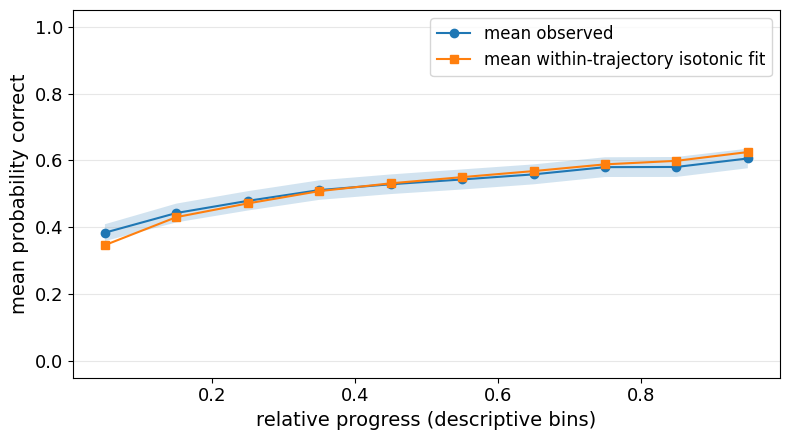

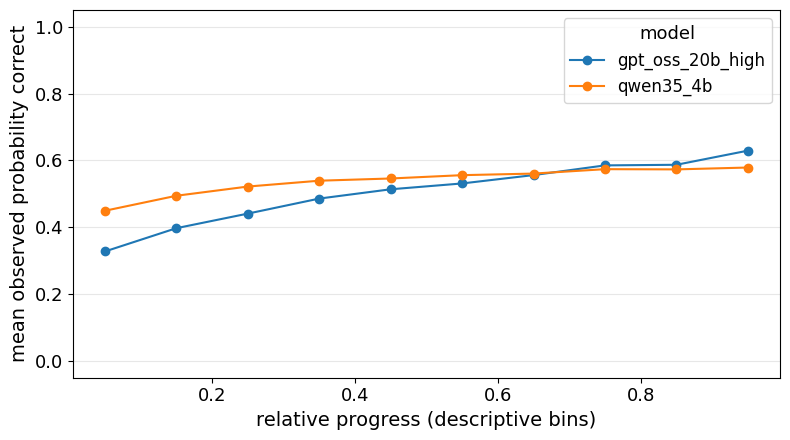

In [ ]:
progress_data = all_regression_curve_data.copy()
progress_data["relative_progress"] = (progress_data["exit_index"] - 1) / progress_data.groupby("trajectory_id")["exit_index"].transform("max").sub(1)
progress_edges = np.linspace(0.0, 1.0, 11)
progress_data["progress_bin"] = pd.cut(progress_data["relative_progress"], bins=progress_edges, labels=False, include_lowest=True)
trajectory_progress = progress_data.groupby(["benchmark", "model", "trajectory_id", "progress_bin"], observed=True, as_index=False).agg(
    p_hat=("p_hat", "mean"), p_isotonic=("p_isotonic", "mean"), exits_in_bin=("position", "size")
)
trajectory_progress["progress_midpoint"] = (progress_edges[trajectory_progress["progress_bin"].astype(int)] + progress_edges[trajectory_progress["progress_bin"].astype(int) + 1]) / 2
mean_regression_by_progress = trajectory_progress.groupby(["progress_bin", "progress_midpoint"], as_index=False).agg(
    trajectories=("trajectory_id", "nunique"), p_hat_mean=("p_hat", "mean"), p_hat_sd=("p_hat", "std"),
    p_isotonic_mean=("p_isotonic", "mean"), p_isotonic_sd=("p_isotonic", "std")
)
for prefix in ["p_hat", "p_isotonic"]:
    sem = mean_regression_by_progress[f"{prefix}_sd"] / np.sqrt(mean_regression_by_progress["trajectories"])
    mean_regression_by_progress[f"{prefix}_ci_low"] = (mean_regression_by_progress[f"{prefix}_mean"] - 1.96 * sem).clip(0, 1)
    mean_regression_by_progress[f"{prefix}_ci_high"] = (mean_regression_by_progress[f"{prefix}_mean"] + 1.96 * sem).clip(0, 1)
mean_regression_by_model_progress = trajectory_progress.groupby(["model", "progress_bin", "progress_midpoint"], as_index=False).agg(
    trajectories=("trajectory_id", "nunique"), p_hat_mean=("p_hat", "mean"), p_isotonic_mean=("p_isotonic", "mean")
)
display(mean_regression_by_progress)
display(mean_regression_by_model_progress)

if plt is None:
    print("Install notebook requirements to render plots: pip install matplotlib")
else:
    fig, axis = plt.subplots(figsize=(8, 4.5))
    x = mean_regression_by_progress["progress_midpoint"].to_numpy()
    axis.plot(x, mean_regression_by_progress["p_hat_mean"], marker="o", label="mean observed")
    axis.fill_between(x, mean_regression_by_progress["p_hat_ci_low"], mean_regression_by_progress["p_hat_ci_high"], alpha=0.2)
    axis.plot(x, mean_regression_by_progress["p_isotonic_mean"], marker="s", label="mean within-trajectory isotonic fit")
    axis.set(xlabel="relative progress (descriptive bins)", ylabel="mean probability correct", ylim=(-0.05, 1.05))
    axis.grid(axis="y", alpha=0.3)
    axis.tick_params(axis="both", labelsize=13)
    axis.xaxis.label.set_size(14)
    axis.yaxis.label.set_size(14)
    axis.legend(fontsize=12)
    fig.tight_layout()

    fig, axis = plt.subplots(figsize=(8, 4.5))
    for model, curve in mean_regression_by_model_progress.groupby("model"):
        axis.plot(curve["progress_midpoint"], curve["p_hat_mean"], marker="o", label=model)
    axis.set(xlabel="relative progress (descriptive bins)", ylabel="mean observed probability correct", ylim=(-0.05, 1.05))
    axis.grid(axis="y", alpha=0.3)
    axis.tick_params(axis="both", labelsize=13)
    axis.xaxis.label.set_size(14)
    axis.yaxis.label.set_size(14)
    axis.legend(title="model", fontsize=12, title_fontsize=13)
    fig.tight_layout()


## Parametric monotone bootstrap

Synthetic counts are drawn from each trajectory's fitted monotone probabilities. The bootstrap recomputes PAVA, $d_i$, $A_i$, and the benchmark/model macro-average for every replicate. This tests whether decoding noise alone could produce at least the observed departure.

In [ ]:
null_bootstrap, null_means, null_trajectory_sample, null_cell_bootstrap = parametric_monotone_bootstrap(
    trajectories,
    replicates=MONOTONE_BOOTSTRAP_REPLICATES,
    seed=BOOTSTRAP_SEED,
)
trajectories = trajectories.merge(null_means, on="trajectory_id", validate="one_to_one")
print(f"Completed {len(null_bootstrap):,} monotone bootstrap replicates")


Completed 1,000 monotone bootstrap replicates


## Question bootstrap

Question IDs are resampled with replacement within benchmark. A sampled ID selects all available models for that question, so models sharing a manifest receive the same resample. This bootstrap quantifies generalization across questions and is kept separate from the decoding-noise bootstrap. Set `RUN_QUESTION_BOOTSTRAP = True` in the configuration cell to run it. When disabled, question-bootstrap confidence intervals are unavailable; observed estimates and monotone-bootstrap p-values are still calculated.

In [ ]:
if RUN_QUESTION_BOOTSTRAP:
    question_samples, question_cell_samples, question_model_samples = question_bootstrap(
        trajectories,
        replicates=QUESTION_BOOTSTRAP_REPLICATES,
        seed=BOOTSTRAP_SEED + 1,
    )
else:
    question_samples = question_cell_samples = question_model_samples = None
headline, benchmark_model, model_summary = summarize(
    trajectories,
    null_bootstrap,
    question_samples,
)
benchmark_model["domain"] = benchmark_model["benchmark"].map(DOMAIN_BY_BENCHMARK).fillna("Unassigned")
domain_summary = benchmark_model.groupby("domain", as_index=False)[["d", "a"]].mean()
domain_summary["a_excess"] = domain_summary["a"] - trajectories.assign(
    domain=trajectories["benchmark"].map(DOMAIN_BY_BENCHMARK).fillna("Unassigned")
).groupby(["domain", "benchmark", "model"], as_index=False)["a_null_mean"].mean().groupby("domain")["a_null_mean"].mean().reindex(domain_summary["domain"]).to_numpy()

display(headline)
display(model_summary)
display(domain_summary)
display(benchmark_model)


,d_overall,d_ci_low,d_ci_high,p_d,a_observed,a_null_expected,a_excess,a_excess_ci_low,a_excess_ci_high,p_a,eligible_trajectories
0,0.597326,NaN,NaN,0.000999,0.021291,0.009205,0.012087,NaN,NaN,0.000999,979


,model,d,a
0,gpt_oss_20b_high,0.742779,0.026626
1,qwen35_4b,0.451873,0.015956


,domain,d,a,a_excess
0,Code,0.493469,0.021447,0.012944
1,Factuality,0.834504,0.032076,0.021537
2,Mathematics,0.467332,0.015936,0.008265
3,Scientific,0.752520,0.023796,0.012848


,benchmark,model,d,a,domain
0,aime26,gpt_oss_20b_high,0.441103,0.008683,Mathematics
1,livecodebench,gpt_oss_20b_high,0.493469,0.021447,Code
2,math500,gpt_oss_20b_high,0.582104,0.025716,Mathematics
3,math500,qwen35_4b,0.378789,0.013409,Mathematics
4,mmlu_pro_subset,gpt_oss_20b_high,0.947235,0.028911,Scientific
5,mmlu_pro_subset,qwen35_4b,0.557806,0.018682,Scientific
6,truthfulqa,gpt_oss_20b_high,1.249985,0.048373,Factuality
7,truthfulqa,qwen35_4b,0.419023,0.015779,Factuality


## Secondary benchmark/model tests

The companion markdown requests detailed benchmark-by-model appendix results and Holm correction when individual significance tests are reported. These tests use each cell's own monotone-bootstrap null and question-bootstrap interval; they are secondary to the macro-averaged headline test.

In [ ]:
secondary_rows = []
for observed in benchmark_model.itertuples(index=False):
    null = null_cell_bootstrap.loc[(null_cell_bootstrap["benchmark"] == observed.benchmark) & (null_cell_bootstrap["model"] == observed.model)]
    question = (question_cell_samples.loc[(question_cell_samples["benchmark"] == observed.benchmark) & (question_cell_samples["model"] == observed.model)]
                if question_cell_samples is not None else None)
    a_null = float(null["a"].mean())
    secondary_rows.append({
        "benchmark": observed.benchmark, "model": observed.model,
        "d_observed": observed.d, "d_null_expected": float(null["d"].mean()), "d_ci_low": question["d"].quantile(0.025) if question is not None else np.nan, "d_ci_high": question["d"].quantile(0.975) if question is not None else np.nan,
        "p_d_raw": (1 + int((null["d"] >= observed.d).sum())) / (len(null) + 1),
        "a_observed": observed.a, "a_null_expected": a_null, "a_excess": observed.a - a_null,
        "a_excess_ci_low": question["a_excess"].quantile(0.025) if question is not None else np.nan, "a_excess_ci_high": question["a_excess"].quantile(0.975) if question is not None else np.nan,
        "p_a_raw": (1 + int((null["a"] >= observed.a).sum())) / (len(null) + 1),
    })
secondary_tests = pd.DataFrame(secondary_rows)
secondary_tests["p_d_holm"] = holm_adjust(secondary_tests["p_d_raw"])
secondary_tests["p_a_holm"] = holm_adjust(secondary_tests["p_a_raw"])
display(secondary_tests)


,benchmark,model,d_observed,d_null_expected,d_ci_low,d_ci_high,p_d_raw,a_observed,a_null_expected,a_excess,a_excess_ci_low,a_excess_ci_high,p_a_raw,p_d_holm,p_a_holm
0,aime26,gpt_oss_20b_high,0.441103,0.202047,NaN,NaN,0.000999,0.008683,0.004165,0.004518,NaN,NaN,0.000999,0.007992,0.007992
1,livecodebench,gpt_oss_20b_high,0.493469,0.169294,NaN,NaN,0.000999,0.021447,0.008503,0.012944,NaN,NaN,0.000999,0.007992,0.007992
2,math500,gpt_oss_20b_high,0.582104,0.271170,NaN,NaN,0.000999,0.025716,0.011749,0.013967,NaN,NaN,0.000999,0.007992,0.007992
3,math500,qwen35_4b,0.378789,0.202225,NaN,NaN,0.000999,0.013409,0.007099,0.006310,NaN,NaN,0.000999,0.007992,0.007992
4,mmlu_pro_subset,gpt_oss_20b_high,0.947235,0.300690,NaN,NaN,0.000999,0.028911,0.010934,0.017976,NaN,NaN,0.000999,0.007992,0.007992
5,mmlu_pro_subset,qwen35_4b,0.557806,0.342966,NaN,NaN,0.000999,0.018682,0.010963,0.007719,NaN,NaN,0.000999,0.007992,0.007992
6,truthfulqa,gpt_oss_20b_high,1.249985,0.242077,NaN,NaN,0.000999,0.048373,0.012806,0.035567,NaN,NaN,0.000999,0.007992,0.007992
7,truthfulqa,qwen35_4b,0.419023,0.242397,NaN,NaN,0.000999,0.015779,0.008271,0.007507,NaN,NaN,0.000999,0.007992,0.007992


## Monotonicity and Exit traps

### Monotonicity figure

Uses `trajectory_progress` and `secondary_tests` computed above.


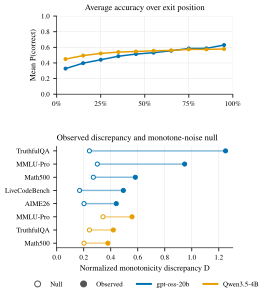

In [ ]:
# Paper-style monotonicity figure from this notebook's in-memory analysis.
from matplotlib.lines import Line2D
PAPER_MODEL_LABELS = {
    "gemma4e4": "Gemma4 E4B", "gpt_oss_20b_high": "gpt-oss-20b",
    "qwen35_4b": "Qwen3.5-4B", "qwen35_9b": "Qwen3.5-9B",
    "r1_qwen3_8b": "R1-Qwen3-8B",
}
PAPER_MODEL_COLORS = {
    "gemma4e4": "#cc79a7", "gpt_oss_20b_high": "#0072b2",
    "qwen35_4b": "#e69f00", "qwen35_9b": "#d55e00",
    "r1_qwen3_8b": "#009e73",
}
PAPER_DATASET_LABELS = {
    "mmlu_pro_subset": "MMLU-Pro", "aime26": "AIME26",
    "truthfulqa": "TruthfulQA", "math500": "Math500",
    "livecodebench": "LiveCodeBench",
}
PAPER_RC = {
    "font.family": "serif", "font.serif": ["Times", "Times New Roman", "STIXGeneral"],
    "mathtext.fontset": "stix", "font.size": 8, "axes.titlesize": 8.5,
    "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "legend.fontsize": 7, "axes.linewidth": .6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6",
    "grid.linewidth": .5, "axes.axisbelow": True, "legend.frameon": False,
    "svg.fonttype": "none",
}

def show_paper_figure(fig):
    """Display a crisp vector figure in Jupyter."""
    from io import StringIO
    from IPython.display import SVG, display
    svg = StringIO()
    fig.savefig(svg, format="svg", bbox_inches="tight", pad_inches=.06)
    display(SVG(data=svg.getvalue()))
    plt.close(fig)

def plot_monotonicity(trajectory_progress, secondary_tests):
    progress = trajectory_progress
    discrepancy = secondary_tests
    models = sorted(discrepancy["model"].unique())
    trend = (progress.groupby(["model", "progress_midpoint"], as_index=False)
             .agg(accuracy=("p_hat", "mean")))
    rows = discrepancy.sort_values(["benchmark", "model"])
    # Keep models adjacent within each dataset, with a gap between datasets.
    y, dataset_centers, dataset_labels = [], [], []
    cursor = 0.
    for benchmark, group in rows.groupby("benchmark", sort=False):
        positions = cursor - .65 * np.arange(len(group))
        y.extend(positions)
        dataset_centers.append(float(positions.mean()))
        dataset_labels.append(PAPER_DATASET_LABELS.get(benchmark, benchmark))
        cursor = positions[-1] - 1.15
    y = np.asarray(y)
    with plt.rc_context(PAPER_RC):
        fig, (ax_top, ax_bottom) = plt.subplots(
            2, 1, figsize=(4.3, max(3.7, .29 * len(rows) + 2.1)),
            gridspec_kw={"height_ratios": [1, 1.3]})
        for model in models:
            curve = trend[trend["model"].eq(model)].sort_values("progress_midpoint")
            ax_top.plot(curve["progress_midpoint"], curve["accuracy"], marker="o",
                        markersize=3, color=PAPER_MODEL_COLORS.get(model, "#666666"),
                        label=PAPER_MODEL_LABELS.get(model, model))
        ax_top.set(xlim=(0, 1), ylim=(0, 1), ylabel="Mean P(correct)",
                   title="Average accuracy over exit position")
        ax_top.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
        for pos, row in zip(y, rows.itertuples()):
            color = PAPER_MODEL_COLORS.get(row.model, "#666666")
            ax_bottom.plot([row.d_null_expected, row.d_observed], [pos, pos],
                           color=color, lw=1.4, alpha=.5)
            ax_bottom.scatter(row.d_null_expected, pos, s=17, facecolor="white",
                              edgecolor=color, zorder=3)
            ax_bottom.scatter(row.d_observed, pos, s=17, color=color, zorder=3)
            ax_bottom.text(1.02, pos, f"{100 * row.a_excess:+.2f}%",
                           transform=ax_bottom.get_yaxis_transform(),
                           ha="left", va="center", fontsize=7, color=color)
        ax_bottom.text(1.02, y[0] + .85, r"$A_{\mathrm{excess}}$",
                       transform=ax_bottom.get_yaxis_transform(),
                       ha="left", va="bottom", fontsize=7)
        ax_bottom.set_ylim(y[-1] - .7, y[0] + 1.3)
        ax_bottom.set_yticks(dataset_centers, dataset_labels)
        ax_bottom.set_xlabel("Normalized monotonicity discrepancy D")
        ax_bottom.set_xlim(left=0)
        ax_bottom.grid(axis="y", visible=False)
        ax_bottom.set_title("Observed discrepancy and monotone-noise null", loc="left")
        ax_bottom.legend(handles=[
            Line2D([], [], ls="", marker="o", markerfacecolor="white",
                   markeredgecolor="#555555", label="Null"),
            Line2D([], [], ls="", marker="o", color="#555555", label="Observed"),
            *[Line2D([], [], color=PAPER_MODEL_COLORS.get(model, "#666666"), lw=2,
                     label=PAPER_MODEL_LABELS.get(model, model)) for model in models]],
            loc="upper center", bbox_to_anchor=(.5, -.27), ncol=2 + len(models))
        fig.subplots_adjust(hspace=.58, left=.33, right=.80, bottom=.15)
        show_paper_figure(fig)

if plt is None:
    print("Install matplotlib to render the monotonicity figure")
else:
    plot_monotonicity(trajectory_progress, secondary_tests)


### Excess reversal beyond decoding noise

The forest plot reports $A_{\mathrm{excess}}$ for every benchmark/model cell. Points are the estimated excess reversal after subtracting the fitted decoding-noise baseline; horizontal bars are 95% question-bootstrap confidence intervals. The vertical line at zero marks no excess deterioration. The complete chart data is displayed immediately above the figure.

In [ ]:
BENCHMARK_LABELS = {"aime26": "AIME26", "math500": "MATH500", "truthfulqa": "TruthfulQA"}
MODEL_LABELS = {"gpt_oss_20b_high": "GPT-OSS", "gpt_oss_20b": "GPT-OSS", "qwen35_4b": "Qwen3.5-4B"}
forest_plot_data = secondary_tests[[
    "benchmark", "model", "a_excess", "a_excess_ci_low", "a_excess_ci_high"
]].copy()
forest_plot_data["label"] = (
    forest_plot_data["benchmark"].map(BENCHMARK_LABELS).fillna(forest_plot_data["benchmark"].str.upper())
    + "\n"
    + forest_plot_data["model"].map(MODEL_LABELS).fillna(forest_plot_data["model"])
)
forest_plot_data["a_excess_percent"] = 100 * forest_plot_data["a_excess"]
forest_plot_data["ci_low_percent"] = 100 * forest_plot_data["a_excess_ci_low"]
forest_plot_data["ci_high_percent"] = 100 * forest_plot_data["a_excess_ci_high"]
display(forest_plot_data)

if not RUN_QUESTION_BOOTSTRAP:
    print("Question bootstrap disabled; forest plot confidence intervals are unavailable.")
elif plt is None:
    print("Install notebook requirements to render plots: pip install matplotlib")
else:
    from matplotlib.ticker import PercentFormatter

    chart = forest_plot_data.reset_index(drop=True)
    y = np.arange(len(chart))
    lower_error = chart["a_excess"] - chart["a_excess_ci_low"]
    upper_error = chart["a_excess_ci_high"] - chart["a_excess"]

    fig, axis = plt.subplots(figsize=(9.5, max(5.5, 1.05 * len(chart) + 2.0)))
    axis.errorbar(
        chart["a_excess"], y, xerr=np.vstack([lower_error, upper_error]),
        fmt="o", markersize=7.5, color="#24557a", ecolor="#6f8fa8",
        elinewidth=2.2, capsize=4, capthick=1.6, zorder=3,
    )
    axis.axvline(0, color="#555555", linewidth=1.2, linestyle="--", zorder=1)
    axis.set_yticks(y, chart["label"])
    axis.invert_yaxis()
    axis.xaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=1))
    axis.set_xlabel(r"$A_{\mathrm{excess}}$ (percentage points)", fontsize=14)
    axis.set_title("Excess reversal beyond decoding noise", loc="left", weight="bold", fontsize=16)
    axis.grid(axis="x", color="#dddddd", linewidth=0.8, alpha=0.8)
    axis.spines[["top", "right", "left"]].set_visible(False)
    axis.tick_params(axis="y", length=0, labelsize=13)
    axis.tick_params(axis="x", labelsize=12)
    right_limit = max(0.01, float(chart["a_excess_ci_high"].max()) * 1.18)
    axis.set_xlim(-0.0025, right_limit)
    for row_y, value in zip(y, chart["a_excess"]):
        axis.annotate(f"{100 * value:.2f}%", (value, row_y), xytext=(7, 7), textcoords="offset points", fontsize=11)
    fig.tight_layout()


,benchmark,model,a_excess,a_excess_ci_low,a_excess_ci_high,label,a_excess_percent,ci_low_percent,ci_high_percent
0,aime26,gpt_oss_20b_high,0.004518,NaN,NaN,AIME26\nGPT-OSS,0.451809,NaN,NaN
1,livecodebench,gpt_oss_20b_high,0.012944,NaN,NaN,LIVECODEBENCH\nGPT-OSS,1.294399,NaN,NaN
2,math500,gpt_oss_20b_high,0.013967,NaN,NaN,MATH500\nGPT-OSS,1.396707,NaN,NaN
3,math500,qwen35_4b,0.006310,NaN,NaN,MATH500\nQwen3.5-4B,0.630973,NaN,NaN
4,mmlu_pro_subset,gpt_oss_20b_high,0.017976,NaN,NaN,MMLU_PRO_SUBSET\nGPT-OSS,1.797639,NaN,NaN
5,mmlu_pro_subset,qwen35_4b,0.007719,NaN,NaN,MMLU_PRO_SUBSET\nQwen3.5-4B,0.771867,NaN,NaN
6,truthfulqa,gpt_oss_20b_high,0.035567,NaN,NaN,TruthfulQA\nGPT-OSS,3.556740,NaN,NaN
7,truthfulqa,qwen35_4b,0.007507,NaN,NaN,TruthfulQA\nQwen3.5-4B,0.750710,NaN,NaN


Question bootstrap disabled; forest plot confidence intervals are unavailable.


## Export reproducible tables

Bootstrap replicate tables are retained so confidence intervals and p-values can be audited without rerunning the analysis.

In [ ]:
TABLE_DIR.mkdir(parents=True, exist_ok=True)
export_tables = {
    "runs": runs,
    "design_audit": design_audit,
    "implementation_checks": implementation_checks,
    "protocol_checks": protocol_checks,
    "completeness": completeness,
    "positions": positions,
    "all_regression_curve_data": all_regression_curve_data,
    "regression_curve_data": regression_curve_data,
    "full_log_sources": full_log_sources,
    "full_log_exit_data": full_log_exit_data,
    "exit_accuracy_text_data": exit_accuracy_text_data,
    "trajectory_progress": trajectory_progress,
    "mean_regression_by_progress": mean_regression_by_progress,
    "mean_regression_by_model_progress": mean_regression_by_model_progress,
    "trajectories": trajectories.drop(columns=["successes", "trials", "isotonic_probabilities"]),
    "headline": headline,
    "models": model_summary,
    "domains": domain_summary,
    "benchmark_model": benchmark_model,
    "secondary_tests_holm": secondary_tests,
    "monotone_bootstrap": null_bootstrap,
    "monotone_cell_bootstrap": null_cell_bootstrap,
    "monotone_trajectory_sample": null_trajectory_sample,
    "forest_plot_data": forest_plot_data,
}
if RUN_QUESTION_BOOTSTRAP:
    export_tables.update({
        "question_bootstrap": question_samples,
        "question_cell_bootstrap": question_cell_samples,
        "question_model_bootstrap": question_model_samples,
    })
for name, table in export_tables.items():
    destination = TABLE_DIR / f"{name}.csv"
    table.to_csv(destination, index=False)
    print(destination)


output/random_exit/analysis/stability/runs.csv
output/random_exit/analysis/stability/design_audit.csv
output/random_exit/analysis/stability/implementation_checks.csv
output/random_exit/analysis/stability/protocol_checks.csv
output/random_exit/analysis/stability/completeness.csv
output/random_exit/analysis/stability/positions.csv
output/random_exit/analysis/stability/all_regression_curve_data.csv
output/random_exit/analysis/stability/regression_curve_data.csv
output/random_exit/analysis/stability/full_log_sources.csv
output/random_exit/analysis/stability/full_log_exit_data.csv
output/random_exit/analysis/stability/exit_accuracy_text_data.csv
output/random_exit/analysis/stability/trajectory_progress.csv
output/random_exit/analysis/stability/mean_regression_by_progress.csv
output/random_exit/analysis/stability/mean_regression_by_model_progress.csv
output/random_exit/analysis/stability/diagnostic_histogram_data.csv
output/random_exit/analysis/stability/diagnostic_ecdf_data.csv
output/rando

## Interpretation checklist

- Use “reject” or “fail to reject monotonicity”; do not claim that a bootstrap test proves nonlinearity.
- Treat this partial run as a pilot until generation is complete and every confirmatory design field matches the plan.
- Report exclusion counts and fractions because extra exits or continuations do not create independent questions.
- Use `d_overall`, its question-bootstrap interval, and `p_d` as the primary result.
- Report `a_observed`, `a_null_expected`, `a_excess`, its question-bootstrap interval, and `p_a` as the effect-size result.
- Treat `secondary_tests_holm.csv` as appendix-level analysis; use its Holm-adjusted p-values rather than the raw benchmark/model p-values.
- Use the exported `*_chart_data.csv`, `*regression*.csv`, `diagnostic_histogram_data.csv`, and `diagnostic_ecdf_data.csv` tables to inspect every plotted value without relying on rendered images.
- Treat the relative-progress mean charts as descriptive only; they do not replace the within-trajectory regression or bootstrap test.

## Test 1: Collapse onset and method traps

This implements the first test in `proposal/predict/reasoning-collapse-detailed.md`. The event-first audit pushes every observed probability to a binary state (`G=1` when $p\geq0.5$, `B=0` otherwise), recognizes Good at `111`, `1101`, or `1011` (three Good states among four checkpoints, with a Good start and end), and emits one or more flags per trace: **Bad before good streak**, **Good→Bad forever**, or **Noisy**. No-event/stable traces are excluded from the event percentage figure.

A Noisy flag is emitted when at least 10 Good/Bad state changes occur within 24 consecutive checkpoints. Overlapping qualifying windows are merged into one interval. A Bad-before-Good trap requires a Bad first checkpoint and an observed later Good pattern. A trace can have multiple trap types, and an all-Good or all-Bad trace can have none. Percentages use all traces as the denominator and need not sum to 100%. Multiple flags from one trace are retained. For every non-baseline early-exit decision in the matched full logs, the audit reports whether the method entered one of these event regions. A `trap failure` is a wrong method answer inside that region.

,event_id,benchmark,model,trajectory_id,data_id,good_position,bad_position,token_gap,p_good,p_bad,drop,recovery_position,recovered_within_observed_trace
0,aime26::gpt_oss_20b_high::aime26:16::collapse@792,aime26,gpt_oss_20b_high,aime26::gpt_oss_20b_high::aime26:16,aime26:16,760,792,32,0.875,0.000,0.875,1016.0,True
1,livecodebench::gpt_oss_20b_high::livecodebench...,livecodebench,gpt_oss_20b_high,livecodebench::gpt_oss_20b_high::livecodebench...,livecodebench:550,847,879,32,1.000,0.125,0.875,NaN,False
2,math500::gpt_oss_20b_high::math500:8::collapse...,math500,gpt_oss_20b_high,math500::gpt_oss_20b_high::math500:8,math500:8,824,856,32,0.875,0.125,0.750,NaN,False
3,math500::gpt_oss_20b_high::math500:272::collap...,math500,gpt_oss_20b_high,math500::gpt_oss_20b_high::math500:272,math500:272,455,487,32,0.875,0.000,0.875,647.0,True
4,math500::gpt_oss_20b_high::math500:1::collapse...,math500,gpt_oss_20b_high,math500::gpt_oss_20b_high::math500:1,math500:1,189,221,32,0.875,0.000,0.875,253.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,truthfulqa::gpt_oss_20b_high::truthfulqa:363::...,truthfulqa,gpt_oss_20b_high,truthfulqa::gpt_oss_20b_high::truthfulqa:363,truthfulqa:363,2330,2394,64,1.000,0.000,1.000,NaN,False
59,truthfulqa::gpt_oss_20b_high::truthfulqa:536::...,truthfulqa,gpt_oss_20b_high,truthfulqa::gpt_oss_20b_high::truthfulqa:536,truthfulqa:536,177,209,32,1.000,0.000,1.000,NaN,False
60,truthfulqa::gpt_oss_20b_high::truthfulqa:567::...,truthfulqa,gpt_oss_20b_high,truthfulqa::gpt_oss_20b_high::truthfulqa:567,truthfulqa:567,4649,4713,64,0.875,0.000,0.875,5321.0,True
61,truthfulqa::gpt_oss_20b_high::truthfulqa:644::...,truthfulqa,gpt_oss_20b_high,truthfulqa::gpt_oss_20b_high::truthfulqa:644,truthfulqa:644,221,253,32,0.875,0.000,0.875,NaN,False


,method,exits,wrong_exits,trap_exits,trap_failures,trap_failure_rate
3,dtsr,858,402,6,6,1.000000
2,deer,831,358,7,5,0.714286
5,entrocut,844,355,7,5,0.714286
1,codestop,861,451,6,5,0.833333
6,puma,728,308,9,4,0.444444
4,dynasor,634,328,7,4,0.571429
9,thought_calibration,756,437,5,4,0.800000
0,answer-coverage,579,263,5,2,0.400000
8,terminator_hf,965,499,3,1,0.333333
7,statistical_early_stop,12,6,0,0,NaN


,model,method,trap_type,trap_exits,trap_type_percent
0,gpt_oss_20b_high,answer-coverage,B,5,100.000000
1,gpt_oss_20b_high,codestop,B,5,83.333333
2,gpt_oss_20b_high,codestop,G,1,16.666667
3,gpt_oss_20b_high,deer,B,6,85.714286
4,gpt_oss_20b_high,deer,G,1,14.285714
5,gpt_oss_20b_high,dtsr,B,5,83.333333
6,gpt_oss_20b_high,dtsr,G,1,16.666667
7,gpt_oss_20b_high,dynasor,B,7,100.000000
8,gpt_oss_20b_high,entrocut,B,6,85.714286
9,gpt_oss_20b_high,entrocut,G,1,14.285714


,model,trajectories,trajectories_with_collapse,method_exits,method_exits_in_trap,trajectories_with_collapse_percent,method_exits_in_trap_percent
0,gpt_oss_20b_high,527,46,3231,55,8.728653,1.702259
1,qwen35_4b,452,6,3837,0,1.327434,0.000000


,benchmark,model,trajectory_id,data_id,method,exit_position,correct,event_id,trap_phase,in_collapse_trap,last_observed_exit_probability,trap_type,failed_in_trap
435,livecodebench,gpt_oss_20b_high,livecodebench::gpt_oss_20b_high::livecodebench...,livecodebench:550,thought_calibration,1408,False,livecodebench::gpt_oss_20b_high::livecodebench...,bad region before recovery,True,0.000,B,True
832,math500,gpt_oss_20b_high,math500::gpt_oss_20b_high::math500:272,math500:272,codestop,463,False,math500::gpt_oss_20b_high::math500:272::collap...,localized onset interval,True,0.875,G,True
833,math500,gpt_oss_20b_high,math500::gpt_oss_20b_high::math500:272,math500:272,deer,463,False,math500::gpt_oss_20b_high::math500:272::collap...,localized onset interval,True,0.875,G,True
834,math500,gpt_oss_20b_high,math500::gpt_oss_20b_high::math500:272,math500:272,dtsr,463,False,math500::gpt_oss_20b_high::math500:272::collap...,localized onset interval,True,0.875,G,True
835,math500,gpt_oss_20b_high,math500::gpt_oss_20b_high::math500:272,math500:272,entrocut,463,False,math500::gpt_oss_20b_high::math500:272::collap...,localized onset interval,True,0.875,G,True
2389,mmlu_pro_subset,gpt_oss_20b_high,mmlu_pro_subset::gpt_oss_20b_high::mmlu_pro_su...,mmlu_pro_subset:1027,terminator_hf,80,True,mmlu_pro_subset::gpt_oss_20b_high::mmlu_pro_su...,bad region before recovery,True,0.125,B,False
2432,mmlu_pro_subset,gpt_oss_20b_high,mmlu_pro_subset::gpt_oss_20b_high::mmlu_pro_su...,mmlu_pro_subset:110,dtsr,1129,False,mmlu_pro_subset::gpt_oss_20b_high::mmlu_pro_su...,bad region before recovery,True,0.125,B,True
2433,mmlu_pro_subset,gpt_oss_20b_high,mmlu_pro_subset::gpt_oss_20b_high::mmlu_pro_su...,mmlu_pro_subset:110,dynasor,1152,False,mmlu_pro_subset::gpt_oss_20b_high::mmlu_pro_su...,bad region before recovery,True,0.000,B,True
2434,mmlu_pro_subset,gpt_oss_20b_high,mmlu_pro_subset::gpt_oss_20b_high::mmlu_pro_su...,mmlu_pro_subset:110,thought_calibration,1152,False,mmlu_pro_subset::gpt_oss_20b_high::mmlu_pro_su...,bad region before recovery,True,0.000,B,True
2484,mmlu_pro_subset,gpt_oss_20b_high,mmlu_pro_subset::gpt_oss_20b_high::mmlu_pro_su...,mmlu_pro_subset:1193,puma,836,True,mmlu_pro_subset::gpt_oss_20b_high::mmlu_pro_su...,bad region before recovery,True,0.125,B,False


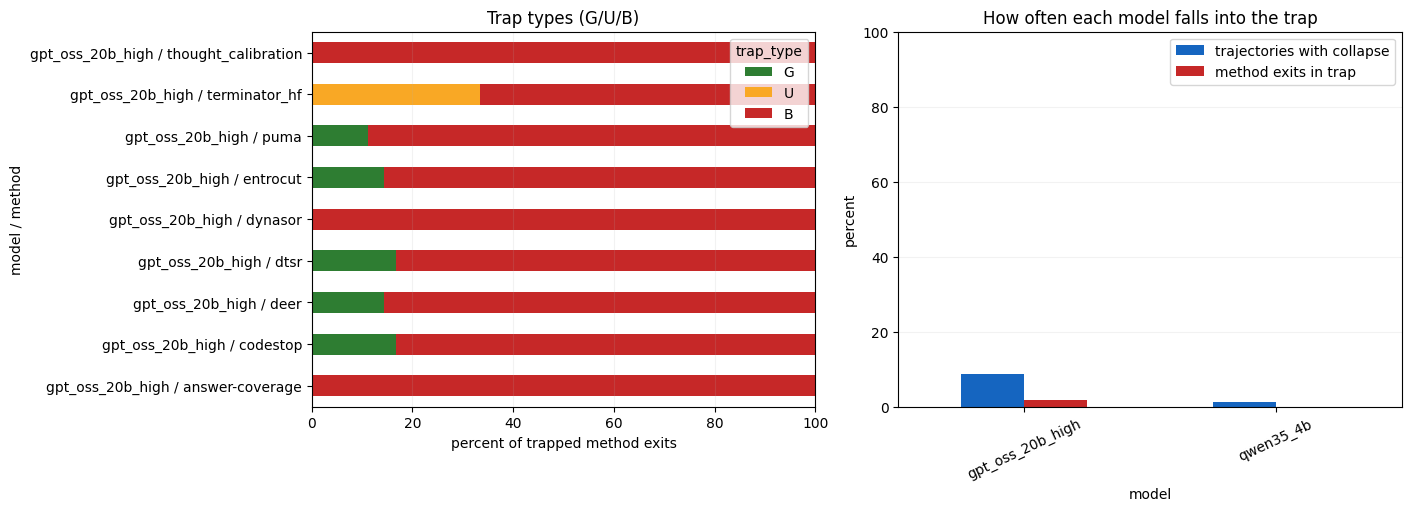

,model,event_type,traces,all_traces,percent
0,gpt_oss_20b_high,Bad before good streak,208,527,39.468691
1,gpt_oss_20b_high,Good-Bad forever,34,527,6.451613
2,gpt_oss_20b_high,Noisy,17,527,3.225806
3,qwen35_4b,Bad before good streak,95,452,21.017699
4,qwen35_4b,Good-Bad forever,11,452,2.433628
5,qwen35_4b,Noisy,23,452,5.088496


,model,dataset,trap_count,avg_trap_length
0,gpt_oss_20b_high,aime26,23,6106.0
1,gpt_oss_20b_high,livecodebench,14,7255.9
2,gpt_oss_20b_high,math500,64,759.0
3,gpt_oss_20b_high,mmlu_pro_subset,105,1430.6
4,gpt_oss_20b_high,truthfulqa,53,1209.8
5,qwen35_4b,math500,35,3579.5
6,qwen35_4b,mmlu_pro_subset,66,3787.7
7,qwen35_4b,truthfulqa,28,8367.9


event_type,model,dataset,Bad before good streak,Good-Bad forever,Noisy
0,gpt_oss_20b_high,aime26,69.0%,3.4%,6.9%
1,gpt_oss_20b_high,livecodebench,12.5%,6.2%,3.1%
2,gpt_oss_20b_high,math500,44.3%,5.7%,2.5%
3,gpt_oss_20b_high,mmlu_pro_subset,48.9%,3.2%,4.3%
4,gpt_oss_20b_high,truthfulqa,27.8%,12.7%,1.6%
5,qwen35_4b,math500,21.1%,1.6%,4.7%
6,qwen35_4b,mmlu_pro_subset,26.0%,2.0%,5.6%
7,qwen35_4b,truthfulqa,13.3%,3.9%,4.7%


,model,method,event_type,exits,trap_failures,all_method_exits,event_exit_percent,percent,failure_rate_within_event_percent
0,gpt_oss_20b_high,answer-coverage,Bad before good streak,12,6,184,6.521739,3.260870,50.000000
1,gpt_oss_20b_high,answer-coverage,Good-Bad forever,5,5,184,2.717391,2.717391,100.000000
2,gpt_oss_20b_high,answer-coverage,Noisy,7,1,184,3.804348,0.543478,14.285714
3,gpt_oss_20b_high,answer-coverage,Other,160,0,184,86.956522,0.000000,0.000000
4,gpt_oss_20b_high,codestop,Bad before good streak,55,41,430,12.790698,9.534884,74.545455
...,...,...,...,...,...,...,...,...,...
65,qwen35_4b,terminator_hf,Noisy,6,1,443,1.354402,0.225734,16.666667
66,qwen35_4b,terminator_hf,Other,426,0,443,96.162528,0.000000,0.000000
67,qwen35_4b,thought_calibration,Bad before good streak,32,27,451,7.095344,5.986696,84.375000
68,qwen35_4b,thought_calibration,Noisy,11,5,451,2.439024,1.108647,45.454545


,model,event_type,methods,avg_traps_faced,avg_trap_exits,avg_inside_interval_exits,avg_fail_total,avg_failure_percent,avg_failure_percent_of_trap
0,gpt_oss_20b_high,Bad before good streak,10,139.4,139.4,34.3,37.4,9.7,25.0
1,gpt_oss_20b_high,Good-Bad forever,10,24.3,24.3,6.5,13.5,3.9,56.0
2,gpt_oss_20b_high,Noisy,10,14.2,14.2,7.3,7.7,2.2,53.3
3,qwen35_4b,Bad before good streak,10,84.1,84.1,14.5,38.2,8.9,40.9
4,qwen35_4b,Good-Bad forever,10,9.9,9.9,1.0,5.1,1.2,51.5
5,qwen35_4b,Noisy,10,20.2,20.2,14.1,11.2,2.6,55.3


,model,method,event_type,all_method_exits,traps_faced,trap_exits,trap_failures,inside_interval_exits,failure_percent,failure_percent_of_trap
0,gpt_oss_20b_high,answer-coverage,Bad before good streak,184,93,93,12,12,6.521739,12.903226
1,gpt_oss_20b_high,answer-coverage,Good-Bad forever,184,17,17,8,5,4.347826,47.058824
2,gpt_oss_20b_high,answer-coverage,Noisy,184,13,13,4,7,2.173913,30.769231
3,gpt_oss_20b_high,codestop,Bad before good streak,430,176,176,64,55,14.883721,36.363636
4,gpt_oss_20b_high,codestop,Good-Bad forever,430,33,33,19,10,4.418605,57.575758
5,gpt_oss_20b_high,codestop,Noisy,430,17,17,10,8,2.325581,58.823529
6,gpt_oss_20b_high,deer,Bad before good streak,409,172,172,28,25,6.845966,16.279070
7,gpt_oss_20b_high,deer,Good-Bad forever,409,31,31,18,10,4.400978,58.064516
8,gpt_oss_20b_high,deer,Noisy,409,17,17,10,8,2.444988,58.823529
9,gpt_oss_20b_high,dtsr,Bad before good streak,426,178,178,45,39,10.563380,25.280899


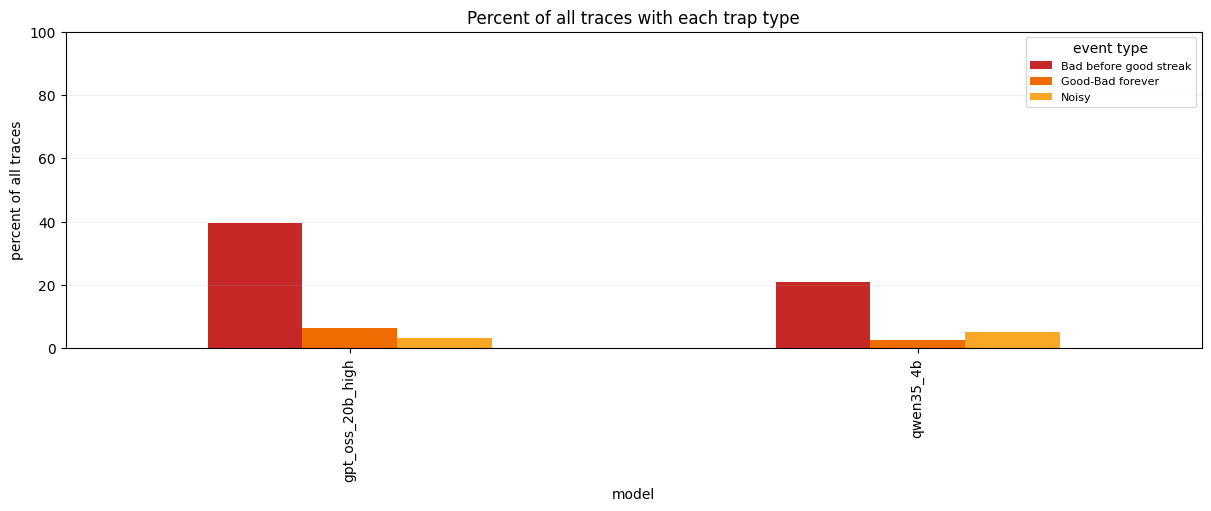

In [ ]:
TEST1_GOOD_THRESHOLD = 0.8
TEST1_BAD_THRESHOLD = 0.2
TEST1_MIN_DROP = 0.6
TEST1_MAX_ONSET_TOKENS = 64

collapse_rows = []
for trajectory_id, curve in all_regression_curve_data.groupby("trajectory_id", sort=False):
    curve = curve.sort_values("position").reset_index(drop=True)
    for onset_index in range(1, len(curve)):
        good, bad = curve.iloc[onset_index - 1], curve.iloc[onset_index]
        token_gap = int(bad.position - good.position)
        if not (good.p_hat >= TEST1_GOOD_THRESHOLD and bad.p_hat <= TEST1_BAD_THRESHOLD and good.p_hat - bad.p_hat >= TEST1_MIN_DROP and token_gap <= TEST1_MAX_ONSET_TOKENS):
            continue
        later_good = curve.loc[(curve.index > onset_index) & (curve["p_hat"] >= TEST1_GOOD_THRESHOLD)]
        recovery_position = int(later_good.iloc[0].position) if not later_good.empty else np.nan
        collapse_rows.append({
            "event_id": f"{trajectory_id}::collapse@{int(bad.position)}",
            "benchmark": bad.benchmark, "model": bad.model, "trajectory_id": trajectory_id, "data_id": bad.data_id,
            "good_position": int(good.position), "bad_position": int(bad.position), "token_gap": token_gap,
            "p_good": float(good.p_hat), "p_bad": float(bad.p_hat), "drop": float(good.p_hat - bad.p_hat),
            "recovery_position": recovery_position, "recovered_within_observed_trace": bool(not later_good.empty),
        })
test1_collapse_events = pd.DataFrame(collapse_rows)

test1_curves = {trajectory_id: curve.sort_values("position") for trajectory_id, curve in all_regression_curve_data.groupby("trajectory_id", sort=False)}
audit_rows = []
for method_exit in full_log_exit_data.itertuples(index=False):
    candidates = test1_collapse_events.loc[test1_collapse_events["trajectory_id"] == method_exit.trajectory_id] if not test1_collapse_events.empty else pd.DataFrame()
    active = candidates.loc[(candidates["good_position"] < method_exit.exit_position) & (candidates["recovery_position"].isna() | (method_exit.exit_position < candidates["recovery_position"]))] if not candidates.empty and pd.notna(method_exit.exit_position) else pd.DataFrame()
    event = active.sort_values("good_position").iloc[-1] if not active.empty else None
    phase = "outside collapse trap" if event is None else ("localized onset interval" if method_exit.exit_position <= event.bad_position else "bad region before recovery")
    in_trap = event is not None
    method_curve = test1_curves.get(method_exit.trajectory_id)
    observed = method_curve.loc[method_curve["position"] <= method_exit.exit_position] if method_curve is not None and pd.notna(method_exit.exit_position) else pd.DataFrame()
    exit_probability = float(observed.iloc[-1].p_hat) if not observed.empty else np.nan
    exit_state = "G" if exit_probability >= TEST1_GOOD_THRESHOLD else ("B" if exit_probability <= TEST1_BAD_THRESHOLD else "U")
    audit_rows.append({
        "benchmark": method_exit.benchmark, "model": method_exit.model, "trajectory_id": method_exit.trajectory_id, "data_id": method_exit.data_id,
        "method": method_exit.method, "exit_position": method_exit.exit_position, "correct": method_exit.correct,
        "event_id": None if event is None else event.event_id, "trap_phase": phase, "in_collapse_trap": in_trap,
        "last_observed_exit_probability": exit_probability, "trap_type": exit_state,
        "failed_in_trap": bool(in_trap and method_exit.correct is not None and not bool(method_exit.correct)),
    })
test1_method_exit_audit = pd.DataFrame(audit_rows)
if test1_method_exit_audit.empty:
    test1_method_summary = pd.DataFrame(columns=["method", "exits", "wrong_exits", "trap_exits", "trap_failures", "trap_failure_rate"])
else:
    test1_method_summary = test1_method_exit_audit.groupby("method", as_index=False).agg(
        exits=("method", "size"), wrong_exits=("correct", lambda values: int(values.eq(False).sum())),
        trap_exits=("in_collapse_trap", "sum"), trap_failures=("failed_in_trap", "sum"),
    )
    test1_method_summary["trap_failure_rate"] = test1_method_summary["trap_failures"] / test1_method_summary["trap_exits"].replace(0, np.nan)

trapped_exits = test1_method_exit_audit.loc[test1_method_exit_audit["in_collapse_trap"]].copy() if not test1_method_exit_audit.empty else pd.DataFrame()
if trapped_exits.empty:
    test1_trap_type_summary = pd.DataFrame(columns=["model", "method", "trap_type", "trap_exits", "trap_type_percent"])
else:
    test1_trap_type_summary = trapped_exits.groupby(["model", "method", "trap_type"], as_index=False).size().rename(columns={"size": "trap_exits"})
    test1_trap_type_summary["trap_type_percent"] = 100 * test1_trap_type_summary["trap_exits"] / test1_trap_type_summary.groupby(["model", "method"])["trap_exits"].transform("sum")

trajectory_denominator = all_regression_curve_data.groupby("model")["trajectory_id"].nunique().rename("trajectories")
collapsed_trajectories = test1_collapse_events.groupby("model")["trajectory_id"].nunique().rename("trajectories_with_collapse") if not test1_collapse_events.empty else pd.Series(dtype=int, name="trajectories_with_collapse")
exit_denominator = test1_method_exit_audit.groupby("model").size().rename("method_exits") if not test1_method_exit_audit.empty else pd.Series(dtype=int, name="method_exits")
trapped_by_model = trapped_exits.groupby("model").size().rename("method_exits_in_trap") if not trapped_exits.empty else pd.Series(dtype=int, name="method_exits_in_trap")
test1_model_trap_summary = pd.concat([trajectory_denominator, collapsed_trajectories, exit_denominator, trapped_by_model], axis=1).fillna(0).reset_index()
for column in ["trajectories", "trajectories_with_collapse", "method_exits", "method_exits_in_trap"]:
    test1_model_trap_summary[column] = test1_model_trap_summary[column].astype(int)
test1_model_trap_summary["trajectories_with_collapse_percent"] = 100 * test1_model_trap_summary["trajectories_with_collapse"] / test1_model_trap_summary["trajectories"].replace(0, np.nan)
test1_model_trap_summary["method_exits_in_trap_percent"] = 100 * test1_model_trap_summary["method_exits_in_trap"] / test1_model_trap_summary["method_exits"].replace(0, np.nan)

test1_collapse_events.to_csv(TABLE_DIR / "test1_collapse_events.csv", index=False)
test1_method_exit_audit.to_csv(TABLE_DIR / "test1_method_exit_audit.csv", index=False)
test1_method_summary.to_csv(TABLE_DIR / "test1_method_summary.csv", index=False)
test1_trap_type_summary.to_csv(TABLE_DIR / "test1_trap_type_summary.csv", index=False)
test1_model_trap_summary.to_csv(TABLE_DIR / "test1_model_trap_summary.csv", index=False)
display(test1_collapse_events)
display(test1_method_summary.sort_values(["trap_failures", "trap_exits"], ascending=False))
display(test1_trap_type_summary)
display(test1_model_trap_summary)
display(trapped_exits)

if plt is None:
    print("Install notebook requirements to render Test 1 percentages: pip install matplotlib")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
    if not test1_trap_type_summary.empty:
        trap_plot = test1_trap_type_summary.assign(series=lambda frame: frame["model"] + " / " + frame["method"]).pivot(index="series", columns="trap_type", values="trap_type_percent").fillna(0).reindex(columns=["G", "U", "B"], fill_value=0)
        trap_plot.plot.barh(stacked=True, ax=axes[0], color=["#2e7d32", "#f9a825", "#c62828"])
    axes[0].set(xlabel="percent of trapped method exits", ylabel="model / method", xlim=(0, 100), title="Trap types (G/U/B)")
    model_plot = test1_model_trap_summary.set_index("model")[["trajectories_with_collapse_percent", "method_exits_in_trap_percent"]].rename(columns={"trajectories_with_collapse_percent": "trajectories with collapse", "method_exits_in_trap_percent": "method exits in trap"})
    model_plot.plot.bar(ax=axes[1], color=["#1565c0", "#c62828"])
    axes[1].set(ylabel="percent", xlabel="model", ylim=(0, 100), title="How often each model falls into the trap")
    axes[1].tick_params(axis="x", rotation=25)
    for axis in axes:
        axis.grid(axis="x" if axis is axes[0] else "y", alpha=0.16)
    test1_chart_path = TABLE_DIR / "test1_trap_percentages.png"
    fig.savefig(test1_chart_path, dpi=180, facecolor="white")
    plt.show()

# Event-first classification: bin every observed p to 0/1 before labeling the trap.
TEST1_BINARY_THRESHOLD = 0.5
TEST1_NOISY_WINDOW = 32
TEST1_NOISY_TRANSITIONS = 10

def classify_test1_events(curve: pd.DataFrame) -> list[dict[str, Any]]:
    curve = curve.sort_values("position").reset_index(drop=True)
    binary = (curve["p_hat"].to_numpy(dtype=float) >= TEST1_BINARY_THRESHOLD).astype(int)
    transitions = int(np.count_nonzero(np.diff(binary)))
    events = []
    # A Good start is 111 or one of the two four-checkpoint patterns with
    # three Good states and Good at both ends: 1101 and 1011.
    def good_end(index: int) -> int | None:
        if index + 3 <= len(binary) and np.all(binary[index:index + 3] == 1):
            return index + 3
        if index + 4 <= len(binary) and tuple(binary[index:index + 4]) in ((1, 1, 0, 1), (1, 0, 1, 1)):
            return index + 4
        return None

    good = next(((index, good_end(index)) for index in range(len(binary)) if good_end(index) is not None), None)
    if good is not None:
        good_start, scan = good
        if good_start > 0 and binary[0] == 0:
            events.append({"event_type": "Bad before good streak", "trap_start": int(curve.iloc[0].position), "trap_end": int(curve.iloc[good_start - 1].position), "transitions": transitions})
        while scan < len(binary):
            bad_index = next((index for index in range(scan, len(binary)) if binary[index] == 0), None)
            if bad_index is None:
                break
            recovery_index = next((index for index in range(bad_index + 1, len(binary)) if binary[index] == 1), None)
            if recovery_index is None:
                events.append({"event_type": "Good-Bad forever", "trap_start": int(curve.iloc[bad_index - 1].position), "trap_end": int(curve.iloc[-1].position), "transitions": transitions})
                break
            scan = recovery_index + 1

    # Count transitions inside each 24-checkpoint window. Merge overlapping
    # qualifying windows so a sustained noisy region remains one event.
    noisy_windows = []
    for start in range(len(binary) - TEST1_NOISY_WINDOW + 1):
        end = start + TEST1_NOISY_WINDOW
        if np.count_nonzero(np.diff(binary[start:end])) >= TEST1_NOISY_TRANSITIONS:
            if noisy_windows and start <= noisy_windows[-1][1]:
                noisy_windows[-1] = (noisy_windows[-1][0], end)
            else:
                noisy_windows.append((start, end))
    if noisy_windows:
        # One Noisy flag per trace, covering every qualifying window.
        start, end = noisy_windows[0][0], noisy_windows[-1][1]
        events.append({"event_type": "Noisy", "trap_start": int(curve.iloc[start].position), "trap_end": int(curve.iloc[end - 1].position), "transitions": int(np.count_nonzero(np.diff(binary[start:end])))})
    return events

event_first_rows = []
for trajectory_id, curve in all_regression_curve_data.groupby("trajectory_id", sort=False):
    events = classify_test1_events(curve)
    for flag_index, event in enumerate(events):
        first = curve.iloc[0]
        event_first_rows.append({"flag_index": flag_index, "trajectory_id": trajectory_id, "benchmark": first.benchmark, "model": first.model, "data_id": first.data_id, **event})
test1_event_first_events = pd.DataFrame(event_first_rows)
if test1_event_first_events.empty:
    test1_model_dataset_trap_summary = pd.DataFrame(columns=["model", "dataset", "trap_count", "avg_trap_length"])
else:
    test1_event_first_events["trap_length"] = test1_event_first_events["trap_end"] - test1_event_first_events["trap_start"] + 1
    test1_model_dataset_trap_summary = test1_event_first_events.groupby(["model", "benchmark"], as_index=False).agg(
        trap_count=("event_type", "size"), avg_trap_length=("trap_length", "mean")
    ).rename(columns={"benchmark": "dataset"})
    test1_model_dataset_trap_summary["avg_trap_length"] = test1_model_dataset_trap_summary["avg_trap_length"].round(1)
    test1_model_dataset_trap_percent = (
        test1_event_first_events.groupby(["model", "benchmark", "event_type"]).size()
        .rename("trap_count").reset_index()
    )
    dataset_trace_totals = all_regression_curve_data.groupby(["model", "benchmark"])["trajectory_id"].nunique().rename("all_traces").reset_index()
    test1_model_dataset_trap_percent = test1_model_dataset_trap_percent.merge(dataset_trace_totals, on=["model", "benchmark"], how="left")
    test1_model_dataset_trap_percent["trap_percent"] = 100 * test1_model_dataset_trap_percent["trap_count"] / test1_model_dataset_trap_percent["all_traces"].replace(0, np.nan)
    test1_model_dataset_trap_percent = test1_model_dataset_trap_percent.pivot_table(index=["model", "benchmark"], columns="event_type", values="trap_percent", fill_value=0).reset_index().rename(columns={"benchmark": "dataset"})
    trap_columns = ["Bad before good streak", "Good-Bad forever", "Noisy"]
    test1_model_dataset_trap_percent = test1_model_dataset_trap_percent.reindex(columns=["model", "dataset"] + trap_columns, fill_value=0)
    test1_model_dataset_trap_percent[trap_columns] = test1_model_dataset_trap_percent[trap_columns].round(1).astype(str) + "%"
if test1_event_first_events.empty:
    test1_model_dataset_trap_percent = pd.DataFrame(columns=["model", "dataset", "Bad before good streak", "Good-Bad forever", "Noisy"])
event_by_trajectory = {trajectory_id: group for trajectory_id, group in test1_event_first_events.groupby("trajectory_id", sort=False)}
event_first_audit_rows = []
for method_exit in full_log_exit_data.itertuples(index=False):
    candidates = event_by_trajectory.get(method_exit.trajectory_id, pd.DataFrame())
    active = candidates.loc[(candidates["trap_start"] <= method_exit.exit_position) & (method_exit.exit_position <= candidates["trap_end"])] if not candidates.empty and pd.notna(method_exit.exit_position) else pd.DataFrame()
    event = active.iloc[-1] if not active.empty else None
    trapped = event is not None
    event_first_audit_rows.append({"benchmark": method_exit.benchmark, "model": method_exit.model, "trajectory_id": method_exit.trajectory_id, "data_id": method_exit.data_id, "method": method_exit.method, "exit_position": method_exit.exit_position, "correct": method_exit.correct, "event_type": event.event_type if trapped else "Other", "in_trap": trapped, "trap_failure": bool(trapped and method_exit.correct is not None and not bool(method_exit.correct))})
test1_event_first_method_audit = pd.DataFrame(event_first_audit_rows)
# Independent per-type prevalence over every trace, including traces with no traps.
trace_totals = all_regression_curve_data.groupby("model")["trajectory_id"].nunique().rename("all_traces")
test1_event_type_summary = (
    test1_event_first_events.groupby(["model", "event_type"])["trajectory_id"].nunique()
    .rename("traces").reset_index()
    if not test1_event_first_events.empty
    else pd.DataFrame(columns=["model", "event_type", "traces"])
)
test1_event_type_summary = test1_event_type_summary.merge(trace_totals.reset_index(), on="model", how="right")
test1_event_type_summary["percent"] = 100 * test1_event_type_summary["traces"] / test1_event_type_summary["all_traces"].replace(0, np.nan)
if test1_event_first_method_audit.empty:
    test1_event_method_summary = pd.DataFrame(columns=["model", "method", "event_type", "exits", "percent", "event_exit_percent", "all_method_exits", "trap_failures", "failure_rate_within_event_percent"])
else:
    test1_event_method_summary = test1_event_first_method_audit.groupby(["model", "method", "event_type"], as_index=False).agg(exits=("event_type", "size"), trap_failures=("trap_failure", "sum"))
    method_totals = test1_event_first_method_audit.groupby(["model", "method"]).size().rename("all_method_exits").reset_index()
    test1_event_method_summary = test1_event_method_summary.merge(method_totals, on=["model", "method"], how="left")
    test1_event_method_summary["event_exit_percent"] = 100 * test1_event_method_summary["exits"] / test1_event_method_summary["all_method_exits"].replace(0, np.nan)
    test1_event_method_summary["percent"] = 100 * test1_event_method_summary["trap_failures"] / test1_event_method_summary["all_method_exits"].replace(0, np.nan)
    test1_event_method_summary["failure_rate_within_event_percent"] = 100 * test1_event_method_summary["trap_failures"] / test1_event_method_summary["exits"].replace(0, np.nan)
# A method faces a trap when its trace has that event, even if it exits
# outside the event interval. Keep the narrower inside-interval count separate.
TEST1_EVENT_TYPES = ["Bad before good streak", "Good-Bad forever", "Noisy"]
method_models = test1_event_first_method_audit[["model", "method"]].drop_duplicates()
if method_models.empty:
    test1_method_trap_failure_percent = pd.DataFrame(columns=["model", "method", "event_type", "traps_faced", "trap_exits", "inside_interval_exits", "trap_failures", "all_method_exits", "failure_percent", "failure_percent_of_trap"])
    test1_method_event_average = pd.DataFrame(columns=["model", "event_type", "methods", "avg_traps_faced", "avg_trap_exits", "avg_inside_interval_exits", "avg_fail_total", "avg_failure_percent", "avg_failure_percent_of_trap"])
else:
    method_event_grid = method_models.merge(pd.DataFrame({"event_type": TEST1_EVENT_TYPES}), how="cross")
    method_totals = test1_event_first_method_audit.groupby(["model", "method"]).size().rename("all_method_exits").reset_index()
    faced_events = test1_event_first_events[["model", "trajectory_id", "event_type"]].drop_duplicates()
    faced_exits = test1_event_first_method_audit.merge(faced_events, on=["model", "trajectory_id"], how="inner", suffixes=("_exit", ""))
    if faced_exits.empty:
        faced_counts = pd.DataFrame(columns=["model", "method", "event_type", "traps_faced", "trap_exits", "trap_failures"])
    else:
        faced_exits["wrong"] = faced_exits["correct"].eq(False)
        faced_counts = faced_exits.groupby(["model", "method", "event_type"], as_index=False).agg(
            traps_faced=("trajectory_id", "nunique"), trap_exits=("event_type", "size"), trap_failures=("wrong", "sum")
        )
    inside_counts = (
        test1_event_first_method_audit.loc[test1_event_first_method_audit["in_trap"]]
        .groupby(["model", "method", "event_type"]).size().rename("inside_interval_exits").reset_index()
    )
    test1_method_trap_failure_percent = method_event_grid.merge(method_totals, on=["model", "method"], how="left")
    test1_method_trap_failure_percent = test1_method_trap_failure_percent.merge(faced_counts, on=["model", "method", "event_type"], how="left")
    test1_method_trap_failure_percent = test1_method_trap_failure_percent.merge(inside_counts, on=["model", "method", "event_type"], how="left")
    count_columns = ["traps_faced", "trap_exits", "inside_interval_exits", "trap_failures"]
    test1_method_trap_failure_percent[count_columns] = test1_method_trap_failure_percent[count_columns].fillna(0).astype(int)
    test1_method_trap_failure_percent["failure_percent"] = 100 * test1_method_trap_failure_percent["trap_failures"] / test1_method_trap_failure_percent["all_method_exits"].replace(0, np.nan)
    test1_method_trap_failure_percent["failure_percent_of_trap"] = 100 * test1_method_trap_failure_percent["trap_failures"] / test1_method_trap_failure_percent["trap_exits"].replace(0, np.nan)
    test1_method_event_average = test1_method_trap_failure_percent.groupby(["model", "event_type"], as_index=False).agg(
        methods=("method", "nunique"),
        avg_traps_faced=("traps_faced", "mean"),
        avg_trap_exits=("trap_exits", "mean"),
        avg_inside_interval_exits=("inside_interval_exits", "mean"),
        avg_fail_total=("trap_failures", "mean"),
        avg_failure_percent=("failure_percent", "mean"),
        avg_failure_percent_of_trap=("failure_percent_of_trap", "mean"),
    )
    for column in test1_method_event_average.columns.difference(["model", "event_type", "methods"]):
        test1_method_event_average[column] = test1_method_event_average[column].round(1)
    test1_method_trap_failure_percent = test1_method_trap_failure_percent.sort_values(["model", "method", "event_type"]).reset_index(drop=True)
    test1_method_event_average = test1_method_event_average.sort_values(["model", "event_type"]).reset_index(drop=True)

test1_event_first_events.to_csv(TABLE_DIR / "test1_event_first_events.csv", index=False)
test1_model_dataset_trap_summary.to_csv(TABLE_DIR / "test1_model_dataset_trap_summary.csv", index=False)
test1_model_dataset_trap_percent.to_csv(TABLE_DIR / "test1_model_dataset_trap_percent.csv", index=False)
test1_event_first_method_audit.to_csv(TABLE_DIR / "test1_event_first_method_audit.csv", index=False)
test1_event_type_summary.to_csv(TABLE_DIR / "test1_event_type_summary.csv", index=False)
test1_event_method_summary.to_csv(TABLE_DIR / "test1_event_method_summary.csv", index=False)
test1_method_event_average.to_csv(TABLE_DIR / "test1_method_event_average.csv", index=False)
test1_method_trap_failure_percent.to_csv(TABLE_DIR / "test1_method_trap_failure_percent.csv", index=False)
display(test1_event_type_summary)
display(test1_model_dataset_trap_summary)
display(test1_model_dataset_trap_percent)
display(test1_event_method_summary)
display(test1_method_event_average)
display(test1_method_trap_failure_percent)
if plt is not None:
    event_plot = test1_event_type_summary.pivot(index="model", columns="event_type", values="percent").fillna(0)
    event_plot = event_plot.reindex(columns=["Bad before good streak", "Good-Bad forever", "Noisy"], fill_value=0)
    fig, axis = plt.subplots(figsize=(12, 5), constrained_layout=True)
    event_plot.plot.bar( ax=axis, color=["#c62828", "#ef6c00", "#f9a825"])
    axis.set(xlabel="model", ylabel="percent of all traces", ylim=(0, 100), title="Percent of all traces with each trap type")
    axis.legend(title="event type", fontsize=8)
    axis.grid(axis="y", alpha=0.16)
    fig.savefig(TABLE_DIR / "test1_event_first_percentages.png", dpi=180, facecolor="white")
    plt.show()


### Exit traps figure

Uses `test1_method_trap_failure_percent` computed in the event-first audit above.


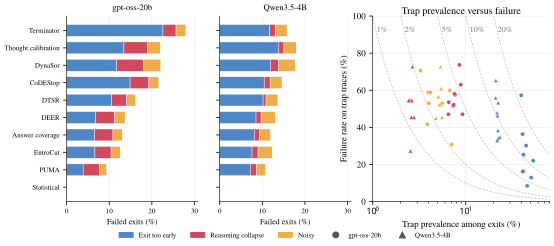

In [ ]:
from matplotlib.lines import Line2D
# Paper-style Exit traps figure from this notebook's event-first audit.
from matplotlib.patches import Patch

TRAP_LABELS = {
    "Bad before good streak": "Exit too early",
    "Good-Bad forever": "Reasoning collapse",
    "Noisy": "Noisy",
}
TRAP_COLORS = {
    "Bad before good streak": "#4f86c6",
    "Good-Bad forever": "#d1495b",
    "Noisy": "#edae49",
}
PAPER_METHOD_LABELS = {
    "answer-coverage": "Answer coverage", "codestop": "CoDEStop",
    "terminator_hf": "Terminator", "statistical_early_stop": "Statistical",
    "thought_calibration": "Thought calibration", "entrocut": "EntroCut",
    "deer": "DEER", "dtsr": "DTSR", "dynasor": "DynaSor", "puma": "PUMA",
}

def plot_exit_traps(test1_method_trap_failure_percent):
    traps = test1_method_trap_failure_percent
    traps = traps[traps["event_type"].isin(TRAP_LABELS)].copy()
    models = list(traps["model"].drop_duplicates())
    methods = (traps.groupby("method")["failure_percent"].sum()
               .sort_values().index.tolist())
    with plt.rc_context(PAPER_RC):
        fig = plt.figure(figsize=(9.2, max(2.6, .29 * len(methods) + .9)))
        grid = fig.add_gridspec(1, len(models) + 1,
                                width_ratios=[1] * len(models) + [1.35], wspace=.15)
        bars = [fig.add_subplot(grid[i]) for i in range(len(models))]
        scatter = fig.add_subplot(grid[-1])
        for ax, model in zip(bars, models):
            left = np.zeros(len(methods))
            for event in TRAP_LABELS:
                subset = traps[traps["model"].eq(model) & traps["event_type"].eq(event)]
                value = np.array([float(subset.loc[subset["method"].eq(m), "failure_percent"].sum())
                                  for m in methods])
                ax.barh(range(len(methods)), value, left=left, height=.68,
                        color=TRAP_COLORS[event], edgecolor="white", lw=.4)
                left += value
            ax.set_title(PAPER_MODEL_LABELS.get(model, model))
            ax.set_xlabel("Failed exits (%)")
            ax.set_yticks(range(len(methods)),
                          [PAPER_METHOD_LABELS.get(m, m) for m in methods] if ax is bars[0] else [])
            ax.set_xlim(0, max(10, float(traps.groupby(["model", "method"])["failure_percent"].sum().max()) * 1.1))
            ax.grid(axis="y", visible=False)
        marker_by_model = {m: marker for m, marker in zip(models, ["o", "^", "s", "D", "v"])}
        prevalence_max = max(80, float(100 * (traps["traps_faced"] / traps["all_method_exits"]).max()) * 1.1)
        x_prevalence = np.logspace(0, np.log10(prevalence_max), 200)
        for total_fail in (1, 2, 5, 10, 20):
            scatter.plot(x_prevalence, 100 * total_fail / x_prevalence,
                         color="#bdbdbd", lw=.7, ls=(0, (3, 2)), zorder=1)
            label_x = max(1.05, 100 * total_fail / 95 * 1.05)
            label_y = min(95, 100 * total_fail / label_x)
            scatter.text(label_x, label_y, f"{total_fail}%", fontsize=8,
                         color="#777777", ha="left", va="bottom")
        for row in traps.itertuples():
            prevalence = 100 * row.traps_faced / row.all_method_exits
            if prevalence <= 0 or not np.isfinite(row.failure_percent_of_trap):
                continue
            scatter.scatter(prevalence, row.failure_percent_of_trap, s=17,
                            marker=marker_by_model[row.model], color=TRAP_COLORS[row.event_type],
                            edgecolor="white", linewidth=.3, zorder=3)
        scatter.set(xscale="log", xlabel="Trap prevalence among exits (%)",
                    ylabel="Failure rate on trap traces (%)", ylim=(0, 100))
        scatter.set_xlim(left=1, right=prevalence_max)
        scatter.set_title("Trap prevalence versus failure", fontsize=10, pad=2)
        scatter.tick_params(labelsize=9)
        scatter.xaxis.label.set_size(9)
        scatter.yaxis.label.set_size(9)
        legend = [Patch(color=TRAP_COLORS[e], label=TRAP_LABELS[e]) for e in TRAP_LABELS]
        legend += [Line2D([], [], ls="", marker=marker_by_model[m], color="#555555",
                          label=PAPER_MODEL_LABELS.get(m, m)) for m in models]
        fig.legend(handles=legend, loc="lower center", bbox_to_anchor=(.5, .04),
                   ncol=min(5, len(legend)))
        fig.subplots_adjust(left=.17, bottom=.2)
        show_paper_figure(fig)

if plt is None:
    print("Install matplotlib to render the Exit traps figure")
else:
    plot_exit_traps(test1_method_trap_failure_percent)


## Model comparison by trap type

The panels use different denominators. **Trap prevalence** is the share of all traces with that trap type. **Failure rate across all exits** is the equal-method average of failures on traces with that trap type divided by all exits for each method. **Failure rate on trap traces** is the equal-method average of failures divided by exits on traces with that trap type; methods with no such exits are excluded from this last average. A trace can contribute to more than one trap type, so Trap % bars need not sum to 100%.


,panel,model,event_type,percent
0,Trap prevalence,gpt_oss_20b_high,Bad before good streak,39.468691
1,Trap prevalence,gpt_oss_20b_high,Good-Bad forever,6.451613
2,Trap prevalence,gpt_oss_20b_high,Noisy,3.225806
3,Trap prevalence,qwen35_4b,Bad before good streak,21.017699
4,Trap prevalence,qwen35_4b,Good-Bad forever,2.433628
5,Trap prevalence,qwen35_4b,Noisy,5.088496
6,Failure rate across all exits,gpt_oss_20b_high,Bad before good streak,9.700000
7,Failure rate across all exits,gpt_oss_20b_high,Good-Bad forever,3.900000
8,Failure rate across all exits,gpt_oss_20b_high,Noisy,2.200000
9,Failure rate across all exits,qwen35_4b,Bad before good streak,8.900000


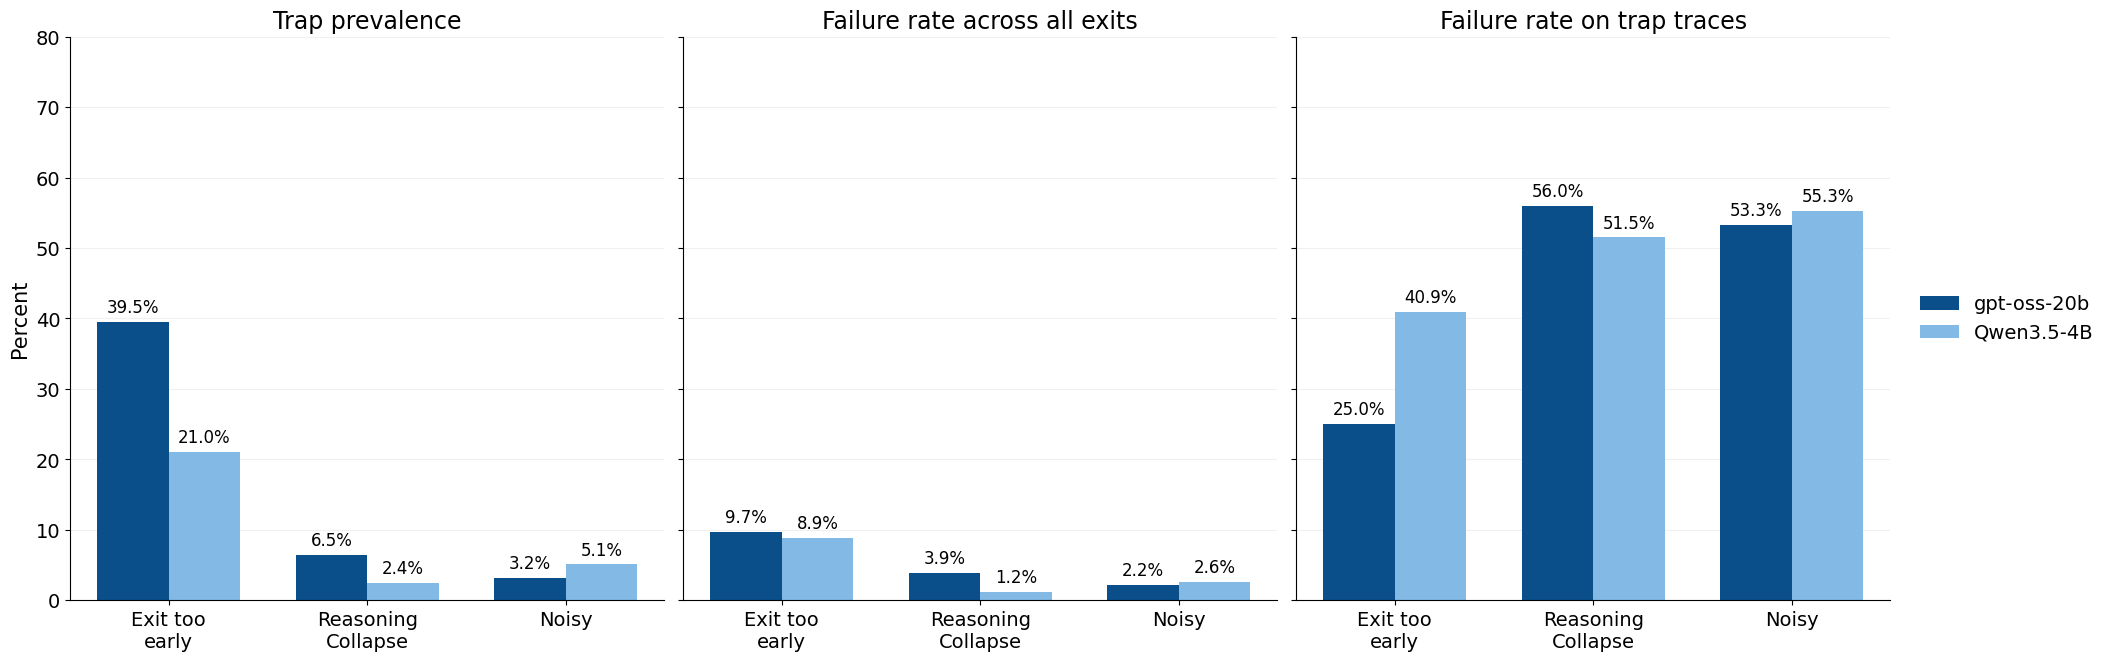

In [ ]:
# Paper comparison: keep the three different denominators in separate panels.
TRAP_ORDER = ["Bad before good streak", "Good-Bad forever", "Noisy"]
TRAP_LABELS = ["Exit too\nearly", "Reasoning\nCollapse", "Noisy"]
MODEL_LABELS = {"gpt_oss_20b_high": "gpt-oss-20b", "qwen35_4b": "Qwen3.5-4B"}
PANEL_METRICS = [
    ("Trap prevalence", "percent", test1_event_type_summary),
    ("Failure rate across all exits", "avg_failure_percent", test1_method_event_average),
    ("Failure rate on trap traces", "avg_failure_percent_of_trap", test1_method_event_average),
]
comparison_rows = []
for panel, value_column, source in PANEL_METRICS:
    for model in MODEL_LABELS:
        for event_type in TRAP_ORDER:
            match = source.loc[(source["model"] == model) & (source["event_type"] == event_type)]
            comparison_rows.append({
                "panel": panel, "model": model, "event_type": event_type,
                "percent": float(match.iloc[0][value_column]) if not match.empty else np.nan,
            })
test1_paper_chart_data = pd.DataFrame(comparison_rows)
test1_paper_chart_data.to_csv(TABLE_DIR / "test1_paper_trap_comparison.csv", index=False)
display(test1_paper_chart_data)

if plt is None:
    print("Install matplotlib to render the model comparison chart")
else:
    fig, axes = plt.subplots(1, 3, figsize=(21, 6.5), sharey=True, constrained_layout=True)
    x = np.arange(len(TRAP_ORDER))
    width = 0.36
    colors = ["#0b4f8a", "#82b9e5"]
    for axis, (panel, _, _source) in zip(axes, PANEL_METRICS):
        panel_data = test1_paper_chart_data.loc[test1_paper_chart_data["panel"] == panel]
        for model_index, (model, label) in enumerate(MODEL_LABELS.items()):
            values = [
                panel_data.loc[(panel_data["model"] == model) & (panel_data["event_type"] == event_type), "percent"].iloc[0]
                for event_type in TRAP_ORDER
            ]
            bars = axis.bar(x + (model_index - 0.5) * width, values, width, color=colors[model_index], label=label)
            for bar, value in zip(bars, values):
                if pd.notna(value):
                    axis.annotate(f"{value:.1f}%", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                                  xytext=(0, 4), textcoords="offset points", ha="center", va="bottom",
                                  fontsize=12, clip_on=False)
        axis.set(title=panel, xticks=x, xticklabels=TRAP_LABELS, ylim=(0, 80))
        axis.title.set_fontsize(17)
        axis.tick_params(axis="both", labelsize=14)
        axis.tick_params(axis="x", labelrotation=0)
        for tick in axis.get_xticklabels():
            tick.set_horizontalalignment("center")
        axis.grid(axis="y", alpha=0.18)
        axis.set_axisbelow(True)
        axis.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("Percent", fontsize=15)
    axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=14, frameon=False)
    comparison_path = TABLE_DIR / "test1_paper_trap_comparison.png"
    fig.savefig(comparison_path, dpi=200, facecolor="white")
    plt.show()
